# Прогнозирование дефолта пользователя банка Ва-банк

**Автор:** Куницын Денис

**Дата:** 3 мая

## Цель и задачи

**Цель:** Построить модель бинарной классификации, которая по историческим данным о клиенте оценивает вероятность дефолта в ближайшие 12 месяцев после даты скоринга.

**Задачи:**
1. Подготовить и объединить разнородные источники данных в единую таблицу наблюдений с учётом временной структуры.
2. Провести исследовательский анализ данных.
3. Создать новые признаки, описывающие поведение клиента и его финансовую историю.
4. Разделить данные на обучающую, калибровочную и тестовую выборки с учётом времени.
5. Обучить и сравнить несколько моделей машинного обучения, включая логистическую регрессию и случайный лес.
6. Подобрать гиперпараметры лучшей модели и оценить её качество по метрикам классификации и бизнес-метрикам.
7. Провести калибровку вероятностей.
8. Проанализировать матрицы ошибок и устойчивость модели на калибровочных и тестовых данных.
9. Оценить важность признаков и сделать выводы о факторах, влияющих на дефолт.

## Данные

В проекте используются данные о клиентах банка, их транзакциях, кредитной истории, макроэкономических показателях и дате скоринга.  
Для построения модели нужно объединить несколько таблиц и корректно учесть временную структуру данных.

Используемые датасеты:

- `loan_payment_credit.csv` — данные о просрочке платежа;
- `transactions.csv` — месячные транзакции клиента;
- `client_description.csv` — описание клиента на момент регистрации в банке;
- `credit_description.csv` — описание кредита;
- `mortgage_presence.csv` — данные о наличии ипотеки;
- `credit_rating.csv` — данные о кредитном рейтинге клиента;
- `macro_data.csv` — данные о макроэкономических показателях России;
- `cohort_grid.csv` — данные о дате проведения поведенческого скоринга.

---

### Описание датасетов

#### 1. `loan_payment_credit.csv`
Данные о просрочке платежа.

- `ID` — идентификатор клиента.
- `дата_начала_периода` — дата начала периода просрочки.
- `просрочка_дней` — длительность просрочки в днях.

#### 2. `transactions.csv`
Месячные транзакции клиента.

- `ID` — идентификатор клиента.
- `date` — календарная дата по месяцам.
- `MCC_5300` — помесячные траты клиента по коду 5300.
- `MCC_5814` — помесячные траты клиента по коду 5814.
- `MCC_5812` — помесячные траты клиента по коду 5812.
- `MCC_5411` — помесячные траты клиента по коду 5411.
- `MCC_3990` — помесячные траты клиента по коду 3990.
- `MCC_5722` — помесячные траты клиента по коду 5722.
- `MCC_4900` — помесячные траты клиента по коду 4900.
- `MCC_другое` — помесячные траты клиента по остальным кодам.

#### 3. `client_description.csv`
Описание клиента на момент регистрации в банке.

- `ID` — идентификатор клиента.
- `возраст` — возраст клиента.
- `семейное_положение` — семейное положение клиента. Три состояния: разведённые, есть семья, нет семьи.
- `наличие_иждивенцев` — есть ли у клиента лица на финансовом попечении: 1 — да, 0 — нет.
- `дата_регистрации` — календарная дата начала взаимоотношений банка и клиента.

#### 4. `credit_description.csv`
Описание кредита.

- `ID` — идентификатор клиента.
- `доход` — месячный доход клиента на момент взятия кредита в рублях.
- `сумма_кредита` — сумма кредита, выданного клиенту, в рублях.

#### 5. `mortgage_presence.csv`
Данные о наличии ипотеки.

- `ID` — идентификатор клиента.
- `дата_открытия` — календарная дата, когда клиент оформил ипотеку.
- `наличие_ипотеки` — есть ли у клиента ипотека: 1 — да, 0 — нет.

#### 6. `credit_rating.csv`
Данные о кредитном рейтинге клиента.

- `ID` — идентификатор клиента.
- `date` — календарная дата получения рейтинга из внешнего источника.
- `кредитный_рейтинг` — значение рейтинга клиента на конкретную дату.

#### 7. `macro_data.csv`
Данные о макроэкономических показателях России.

- `date` — месяц и год, на которые актуальны указанные показатели.
- `учетная_ставка` — учётная ставка в процентах.
- `уровень_безработицы` — уровень безработицы в процентах.
- `инфляция` — инфляция в процентах.

#### 8. `cohort_grid.csv`
Данные о дате проведения поведенческого скоринга.

- `ID` — идентификатор клиента.
- `score_date` — дата скоринга.

---

## Структура проекта

1. Загрузка необходимых библиотек  
2. Загрузка данных  
3. Исследовательский анализ данных  
4. Объединение таблиц  
5. Создание новых признаков  
6. Анализ итоговой таблицы  
7. Моделирование  
8. Калибровка модели и пересчёт результатов  
9. Поиск порога решения  
10. Анализ матрицы ошибок  
11. Фиксация итоговой модели  
12. Анализ важности признаков  
13. Отчет о проделанной работе. Результаты

---

## 1. Загрузка необходимых библиотек

In [1]:
requirements_txt = """pandas==2.2.3
numpy==2.0.2
matplotlib==3.9.4
phik==0.12.5
seaborn==0.13.2
scikit-learn==1.5.2
imbalanced-learn==0.14.0
mlxtend==0.22.0
optuna==3.5.0
dotenv==0.9.9
joblib==1.4.2
"""

with open('requirements.txt', 'w', encoding='utf-8') as f:
    f.write(requirements_txt)

!pip -q install -r requirements.txt


[notice] A new release of pip is available: 24.2 -> 26.1.1
[notice] To update, run: pip install --upgrade pip


In [2]:
from IPython.display import display
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
import phik
import optuna
import joblib
from dotenv import load_dotenv
import os

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import cross_validate, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import make_scorer, accuracy_score, confusion_matrix, roc_auc_score, precision_score, recall_score, brier_score_loss, ConfusionMatrixDisplay
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from mlxtend.evaluate.time_series import GroupTimeSeriesSplit
from sklearn.calibration import calibration_curve, CalibrationDisplay, CalibratedClassifierCV

venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
# Закрепление используемых значений
RANDOM_STATE = 627

**Все необходимые инструменты успешно загружены**

---

## 2. Загрузка данных

In [4]:
load_dotenv()

base_url = os.getenv("DATASET_BASE_URL")

dataset_files = {
    "loan_payment_credit": os.getenv("DATASET_LOAN_PAYMENT_URL"),
    "transactions": os.getenv("DATASET_TRANSACTIONS_URL"),
    "client_description": os.getenv("DATASET_CLIENT_DESCRIPTION_URL"),
    "credit_description": os.getenv("DATASET_CREDIT_DESCRIPTION_URL"),
    "mortgage_presence": os.getenv("DATASET_MORTGAGE_URL"),
    "credit_rating": os.getenv("DATASET_CREDIT_RATING_URL"),
    "macro_data": os.getenv("DATASET_MACRO_URL"),
    "cohort_grid": os.getenv("DATASET_COHORT_GRID_URL"),
}

datasets = {}

for name, filename in dataset_files.items():
    print("\n" + "=" * 60)
    print(f"{name.upper()}")
    print("=" * 60)

    url = base_url + filename
    df = pd.read_csv(url)
    datasets[name] = df

    print(f"Строк: {df.shape[0]:,} | Столбцов: {df.shape[1]:,}")
    print("\nПервые 5 строк:")
    display(df.head())

    print("\nИнформация о датасете:")
    df.info()


LOAN_PAYMENT_CREDIT
Строк: 5,500 | Столбцов: 3

Первые 5 строк:


,ID,дата_начала_периода,просрочка_дней
0,IDF55109846,2014-12-01,120
1,IDF54995533,2015-06-01,121
2,IDF54964538,2018-03-01,87
3,IDF55079777,2019-09-01,109
4,IDF55093915,2017-02-01,84



Информация о датасете:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5500 entries, 0 to 5499
Data columns (total 3 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   ID                   5500 non-null   object
 1   дата_начала_периода  5500 non-null   object
 2   просрочка_дней       5500 non-null   int64 
dtypes: int64(1), object(2)
memory usage: 129.0+ KB

TRANSACTIONS
Строк: 577,494 | Столбцов: 10

Первые 5 строк:


,ID,date,MCC_5300,MCC_5814,MCC_5812,MCC_5411,MCC_3990,MCC_5722,MCC_4900,MCC_другое
0,IDF55109846,2013-05-01,3267.59,1282.11,1457.96,5711.10,647.43,2374.78,4059.86,3657.35
1,IDF55109846,2013-06-01,3196.58,2443.37,1334.20,5824.65,1067.55,2187.11,4592.26,3322.61
2,IDF55109846,2013-07-01,3550.54,4277.72,1463.75,5209.51,1167.95,2076.54,3605.25,3467.06
3,IDF55109846,2013-08-01,3385.98,4530.63,1261.40,5765.96,986.99,2231.77,2209.39,3354.44
4,IDF55109846,2013-09-01,3214.84,4146.65,1405.15,5632.11,640.76,2156.67,1519.46,4352.90



Информация о датасете:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 577494 entries, 0 to 577493
Data columns (total 10 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   ID          577494 non-null  object 
 1   date        577494 non-null  object 
 2   MCC_5300    577494 non-null  float64
 3   MCC_5814    577494 non-null  float64
 4   MCC_5812    577494 non-null  float64
 5   MCC_5411    577494 non-null  float64
 6   MCC_3990    577494 non-null  float64
 7   MCC_5722    577494 non-null  float64
 8   MCC_4900    577494 non-null  float64
 9   MCC_другое  577494 non-null  float64
dtypes: float64(8), object(2)
memory usage: 44.1+ MB

CLIENT_DESCRIPTION
Строк: 13,500 | Столбцов: 5

Первые 5 строк:


,ID,возраст,семейное_положение,наличие_иждивенцев,дата_регистрации
0,IDF55109846,41,разведённые,1,2013-05-01
1,IDF54900291,45,разведённые,1,2017-12-01
2,IDF54995533,34,разведённые,1,2013-11-01
3,IDF55065581,40,нет семьи,1,2018-08-01
4,IDF55057353,66,разведённые,0,2018-05-01


... (7 outputs left out)

,date,учетная_ставка,уровень_безработицы,инфляция
0,2013-01-01,5.5,5.7,0.97
1,2013-02-01,5.5,5.8,0.56
2,2013-03-01,5.5,5.9,0.34
3,2013-04-01,5.5,5.5,0.51
4,2013-05-01,5.5,5.4,0.66



Информация о датасете:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 84 entries, 0 to 83
Data columns (total 4 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   date                 84 non-null     object 
 1   учетная_ставка       84 non-null     float64
 2   уровень_безработицы  84 non-null     float64
 3   инфляция             84 non-null     float64
dtypes: float64(3), object(1)
memory usage: 2.8+ KB

COHORT_GRID
Строк: 577,494 | Столбцов: 2

Первые 5 строк:


,ID,score_date
0,IDF55109846,2013-05-01
1,IDF55109846,2013-06-01
2,IDF55109846,2013-07-01
3,IDF55109846,2013-08-01
4,IDF55109846,2013-09-01



Информация о датасете:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 577494 entries, 0 to 577493
Data columns (total 2 columns):
 #   Column      Non-Null Count   Dtype 
---  ------      --------------   ----- 
 0   ID          577494 non-null  object
 1   score_date  577494 non-null  object
dtypes: object(2)
memory usage: 8.8+ MB


#### Выводы по первичному анализу данных

Все данные соотвествуют своему описанию и до объединения в витрину данных не содержат пропусков.

Можно проводить исследовательский анализ данных и применять данные в работе. Также, будет необходимо привести временные данные к типу `datetime` для удобства обработки.

---

## 3. Исследовательский анализ данных

### 3.1 Создание функций для удобства анализа

In [5]:
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 200)
pd.set_option("display.max_rows", 200)

DATASET_ENV_MAP = {
    "loan_payment_credit": "DATASET_LOAN_PAYMENT_URL",
    "transactions": "DATASET_TRANSACTIONS_URL",
    "client_description": "DATASET_CLIENT_DESCRIPTION_URL",
    "credit_description": "DATASET_CREDIT_DESCRIPTION_URL",
    "mortgage_presence": "DATASET_MORTGAGE_URL",
    "credit_rating": "DATASET_CREDIT_RATING_URL",
    "macro_data": "DATASET_MACRO_URL",
    "cohort_grid": "DATASET_COHORT_GRID_URL",
}

def detect_date_columns(df):
    return [
        c for c in df.columns
        if "date" in c.lower() or "дата" in c.lower()
    ]

def ensure_dataset_loaded(dataset_key):
    if dataset_key in datasets:
        return datasets[dataset_key]

    env_name = DATASET_ENV_MAP.get(dataset_key)
    filename = os.getenv(env_name) if env_name else None
    if dataset_key == "client_description" and not filename:
        filename = "client_description.csv"
    if not (base_url and filename):
        raise KeyError(f"Не удалось загрузить датасет {dataset_key}: нет base_url или имени файла.")

    datasets[dataset_key] = pd.read_csv(base_url + filename)
    return datasets[dataset_key]

def run_dataset_eda(
    dataset_key,
    title,
    date_cols_hint=None,
):
    df = ensure_dataset_loaded(dataset_key).copy()
    print("=" * 90)
    print(f"EDA: {title} ({dataset_key})")
    print("=" * 90)
    print(f"Размер: {df.shape[0]:,} строк x {df.shape[1]:,} столбцов")

    date_cols = set(detect_date_columns(df))
    if date_cols_hint:
        date_cols.update(date_cols_hint)
    date_cols = [c for c in date_cols if c in df.columns]
    for col in date_cols:
        df[col] = pd.to_datetime(df[col], errors="coerce")

    print("\nПервые 5 строк:")
    display(df.head())

    print("\nТипы данных:")
    display(df.dtypes.to_frame("dtype"))

    miss = (
        df.isna()
        .sum()
        .rename("missing_count")
        .to_frame()
        .assign(missing_share=lambda x: (x["missing_count"] / len(df) * 100).round(2))
        .sort_values("missing_count", ascending=False)
    )
    print("\nПропуски по столбцам:")
    display(miss)

    dup_count = int(df.duplicated().sum())
    dup_share = round(dup_count / len(df) * 100, 2) if len(df) else 0
    print(f"\nПолных дубликатов: {dup_count:,} ({dup_share}%)")

    id_cols = ["ID"] if "ID" in df.columns else []

    numeric_cols = [
        c for c in df.select_dtypes(include=["number"]).columns
        if c not in id_cols
    ]
    cat_cols = [
        c for c in df.select_dtypes(include=["object", "category", "bool"]).columns
        if c not in id_cols
    ]

    if numeric_cols:
        print("\nОписательная статистика числовых признаков:")
        display(df[numeric_cols].describe().T)

    if cat_cols:
        print("\nКардинальность категориальных признаков:")
        display(df[cat_cols].nunique(dropna=False).sort_values(ascending=False).to_frame("nunique"))

    return df

### 3.2 loan_payment_credit


EDA: Просрочки по кредитам (loan_payment_credit)
Размер: 5,500 строк x 3 столбцов

Первые 5 строк:


,ID,дата_начала_периода,просрочка_дней
0,IDF55109846,2014-12-01,120
1,IDF54995533,2015-06-01,121
2,IDF54964538,2018-03-01,87
3,IDF55079777,2019-09-01,109
4,IDF55093915,2017-02-01,84



Типы данных:


,dtype
ID,object
дата_начала_периода,datetime64[ns]
просрочка_дней,int64



Пропуски по столбцам:


,missing_count,missing_share
ID,0,0.0
дата_начала_периода,0,0.0
просрочка_дней,0,0.0



Полных дубликатов: 0 (0.0%)

Описательная статистика числовых признаков:


,count,mean,std,min,25%,50%,75%,max
просрочка_дней,5500.0,114.748,20.362422,80.0,97.0,115.0,132.0,150.0


venv/lib/python3.12/site-packages/scipy/_lib/_util.py:1235: RuntimeWarning: divide by zero encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
venv/lib/python3.12/site-packages/scipy/_lib/_util.py:1235: RuntimeWarning: overflow encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
venv/lib/python3.12/site-packages/scipy/_lib/_util.py:1235: RuntimeWarning: invalid value encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)


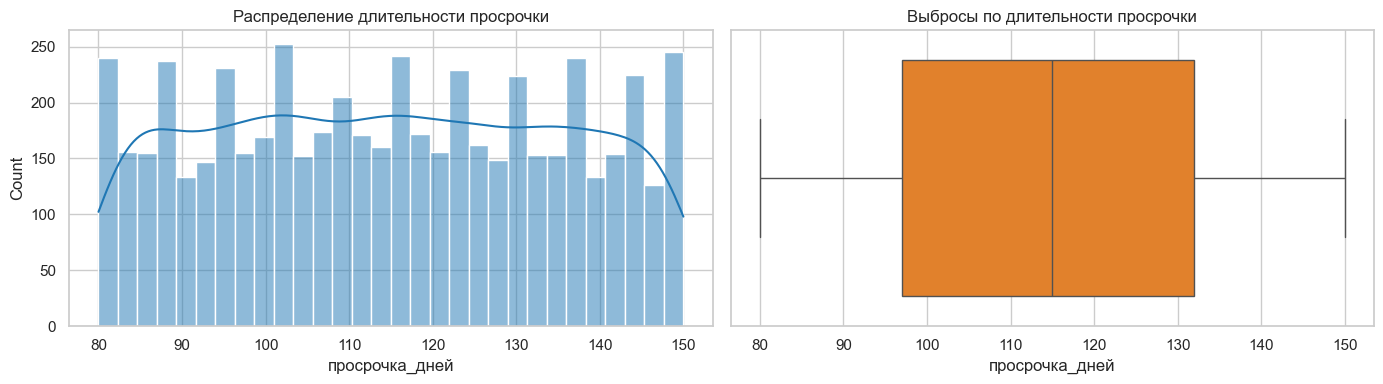

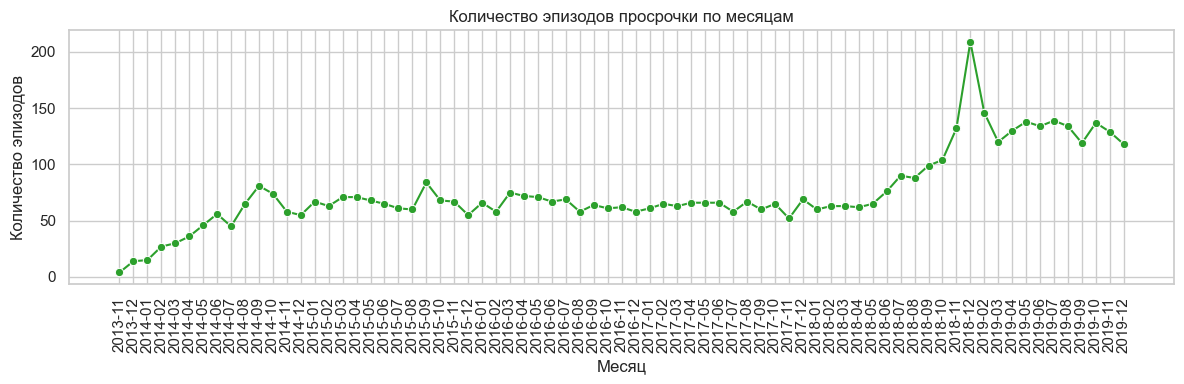

In [6]:
df_loan = run_dataset_eda(
    dataset_key="loan_payment_credit",
    title="Просрочки по кредитам",
    date_cols_hint=["дата_начала_периода"],
)

if {"дата_начала_периода", "просрочка_дней"}.issubset(df_loan.columns):
    df_loan["дата_начала_периода"] = pd.to_datetime(df_loan["дата_начала_периода"], errors="coerce")

    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    sns.histplot(df_loan["просрочка_дней"].dropna(), bins=30, kde=True, ax=axes[0], color="#1f77b4")
    axes[0].set_title("Распределение длительности просрочки")
    axes[0].set_xlabel("просрочка_дней")

    sns.boxplot(x=df_loan["просрочка_дней"], ax=axes[1], color="#ff7f0e")
    axes[1].set_title("Выбросы по длительности просрочки")
    axes[1].set_xlabel("просрочка_дней")

    plt.tight_layout()
    plt.show()

    loan_monthly = (
        df_loan.dropna(subset=["дата_начала_периода"])
        .groupby(df_loan.dropna(subset=["дата_начала_периода"])["дата_начала_периода"].dt.to_period("M"))
        .size()
        .sort_index()
    )

    plt.figure(figsize=(12, 4))
    sns.lineplot(x=loan_monthly.index.astype(str), y=loan_monthly.values, marker="o", color="#2ca02c")
    plt.title("Количество эпизодов просрочки по месяцам")
    plt.xlabel("Месяц")
    plt.ylabel("Количество эпизодов")
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.show()
else:
    print("Ожидаемые столбцы для визуализаций loan_payment_credit не найдены.")

### 3.3 transactions


EDA: Транзакции по MCC (transactions)
Размер: 577,494 строк x 10 столбцов

Первые 5 строк:


,ID,date,MCC_5300,MCC_5814,MCC_5812,MCC_5411,MCC_3990,MCC_5722,MCC_4900,MCC_другое
0,IDF55109846,2013-05-01,3267.59,1282.11,1457.96,5711.10,647.43,2374.78,4059.86,3657.35
1,IDF55109846,2013-06-01,3196.58,2443.37,1334.20,5824.65,1067.55,2187.11,4592.26,3322.61
2,IDF55109846,2013-07-01,3550.54,4277.72,1463.75,5209.51,1167.95,2076.54,3605.25,3467.06
3,IDF55109846,2013-08-01,3385.98,4530.63,1261.40,5765.96,986.99,2231.77,2209.39,3354.44
4,IDF55109846,2013-09-01,3214.84,4146.65,1405.15,5632.11,640.76,2156.67,1519.46,4352.90



Типы данных:


,dtype
ID,object
date,datetime64[ns]
MCC_5300,float64
MCC_5814,float64
MCC_5812,float64
MCC_5411,float64
MCC_3990,float64
MCC_5722,float64
MCC_4900,float64
MCC_другое,float64



Пропуски по столбцам:


,missing_count,missing_share
ID,0,0.0
date,0,0.0
MCC_5300,0,0.0
MCC_5814,0,0.0
MCC_5812,0,0.0
MCC_5411,0,0.0
MCC_3990,0,0.0
MCC_5722,0,0.0
MCC_4900,0,0.0
MCC_другое,0,0.0



Полных дубликатов: 0 (0.0%)

Описательная статистика числовых признаков:


,count,mean,std,min,25%,50%,75%,max
MCC_5300,577494.0,6177.123479,8835.871514,162.91,1360.8800,2659.590,6561.4675,86939.40
MCC_5814,577494.0,3507.682295,5710.755226,62.18,583.4800,1233.110,3642.3925,55720.69
MCC_5812,577494.0,2993.862550,4541.119582,67.06,611.5400,1224.530,3201.6125,47969.57
MCC_5411,577494.0,9263.099506,12299.732992,286.11,2139.4800,4115.385,9287.5450,101301.95
MCC_3990,577494.0,1128.116742,1557.157475,31.90,245.0600,476.890,1159.5200,14261.49
MCC_5722,577494.0,3604.437043,5005.896972,108.40,824.9425,1590.120,3866.0500,54630.19
MCC_4900,577494.0,3682.487182,5567.979383,81.29,700.6325,1397.065,3872.4125,52987.53
MCC_другое,577494.0,5414.896895,7190.882383,166.26,1250.8500,2398.330,5413.5300,60033.55


venv/lib/python3.12/site-packages/scipy/_lib/_util.py:1235: RuntimeWarning: divide by zero encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
venv/lib/python3.12/site-packages/scipy/_lib/_util.py:1235: RuntimeWarning: overflow encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
venv/lib/python3.12/site-packages/scipy/_lib/_util.py:1235: RuntimeWarning: invalid value encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)


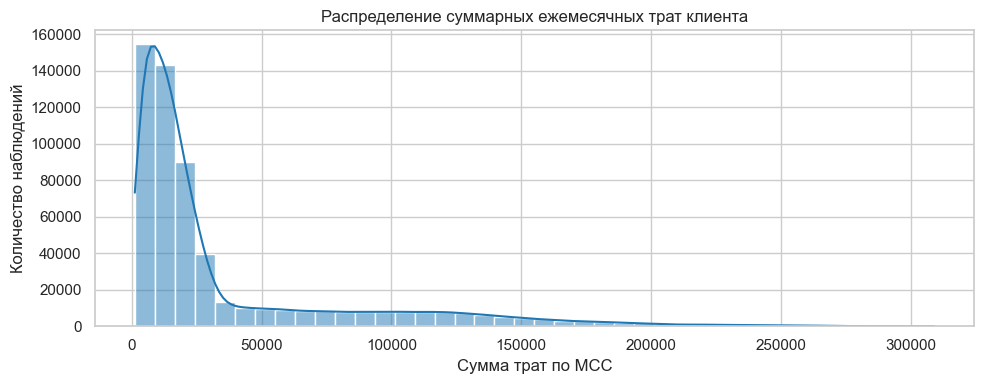

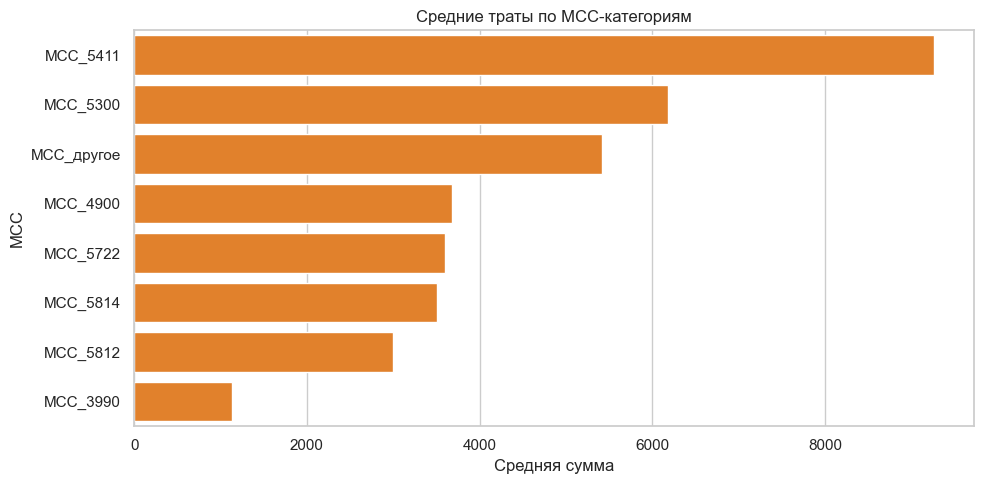

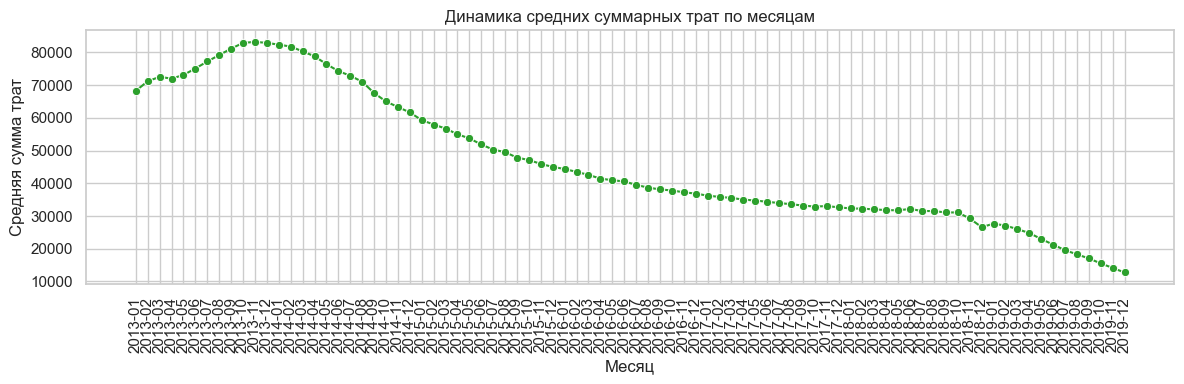

In [7]:
df_tr = run_dataset_eda(
    dataset_key="transactions",
    title="Транзакции по MCC",
    date_cols_hint=["date"],
)

if "date" in df_tr.columns:
    df_tr["date"] = pd.to_datetime(df_tr["date"], errors="coerce")

mcc_cols = [c for c in df_tr.columns if c.startswith("MCC_")]
if mcc_cols:
    df_tr["total_mcc_spend"] = df_tr[mcc_cols].sum(axis=1)

    plt.figure(figsize=(10, 4))
    sns.histplot(df_tr["total_mcc_spend"].dropna(), bins=40, kde=True, color="#1f77b4")
    plt.title("Распределение суммарных ежемесячных трат клиента")
    plt.xlabel("Сумма трат по MCC")
    plt.ylabel("Количество наблюдений")
    plt.tight_layout()
    plt.show()

    mcc_mean = df_tr[mcc_cols].mean().sort_values(ascending=False)
    plt.figure(figsize=(10, 5))
    sns.barplot(x=mcc_mean.values, y=mcc_mean.index, color="#ff7f0e")
    plt.title("Средние траты по MCC-категориям")
    plt.xlabel("Средняя сумма")
    plt.ylabel("MCC")
    plt.tight_layout()
    plt.show()

    if "date" in df_tr.columns:
        monthly_spend = (
            df_tr.dropna(subset=["date"])
            .groupby(df_tr.dropna(subset=["date"])["date"].dt.to_period("M"))["total_mcc_spend"]
            .mean()
            .sort_index()
        )
        plt.figure(figsize=(12, 4))
        sns.lineplot(x=monthly_spend.index.astype(str), y=monthly_spend.values, marker="o", color="#2ca02c")
        plt.title("Динамика средних суммарных трат по месяцам")
        plt.xlabel("Месяц")
        plt.ylabel("Средняя сумма трат")
        plt.xticks(rotation=90)
        plt.tight_layout()
        plt.show()
else:
    print("Столбцы MCC_ для визуализации transactions не найдены.")

### 3.4 client_description


EDA: Описание клиента (client_description)
Размер: 13,500 строк x 5 столбцов

Первые 5 строк:


,ID,возраст,семейное_положение,наличие_иждивенцев,дата_регистрации
0,IDF55109846,41,разведённые,1,2013-05-01
1,IDF54900291,45,разведённые,1,2017-12-01
2,IDF54995533,34,разведённые,1,2013-11-01
3,IDF55065581,40,нет семьи,1,2018-08-01
4,IDF55057353,66,разведённые,0,2018-05-01



Типы данных:


,dtype
ID,object
возраст,int64
семейное_положение,object
наличие_иждивенцев,int64
дата_регистрации,datetime64[ns]



Пропуски по столбцам:


,missing_count,missing_share
ID,0,0.0
возраст,0,0.0
семейное_положение,0,0.0
наличие_иждивенцев,0,0.0
дата_регистрации,0,0.0



Полных дубликатов: 0 (0.0%)

Описательная статистика числовых признаков:


,count,mean,std,min,25%,50%,75%,max
возраст,13500.0,41.304815,15.096673,18.0,28.0,40.0,54.0,69.0
наличие_иждивенцев,13500.0,0.484741,0.499786,0.0,0.0,0.0,1.0,1.0



Кардинальность категориальных признаков:


,nunique
семейное_положение,3


venv/lib/python3.12/site-packages/scipy/_lib/_util.py:1235: RuntimeWarning: divide by zero encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
venv/lib/python3.12/site-packages/scipy/_lib/_util.py:1235: RuntimeWarning: overflow encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
venv/lib/python3.12/site-packages/scipy/_lib/_util.py:1235: RuntimeWarning: invalid value encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)


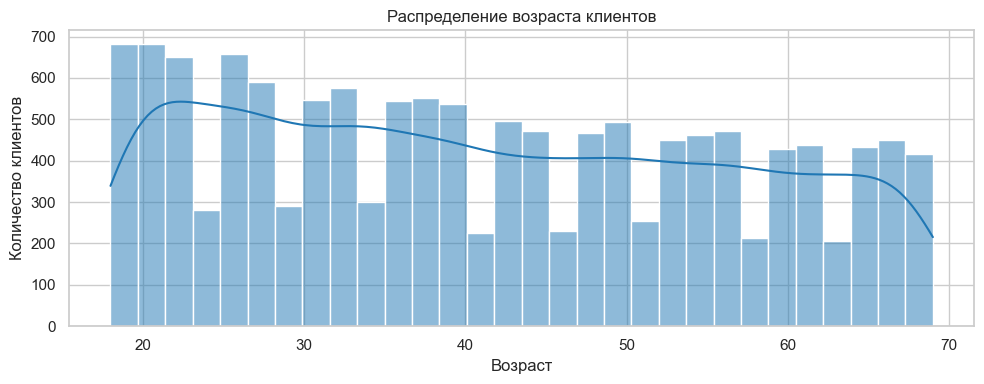

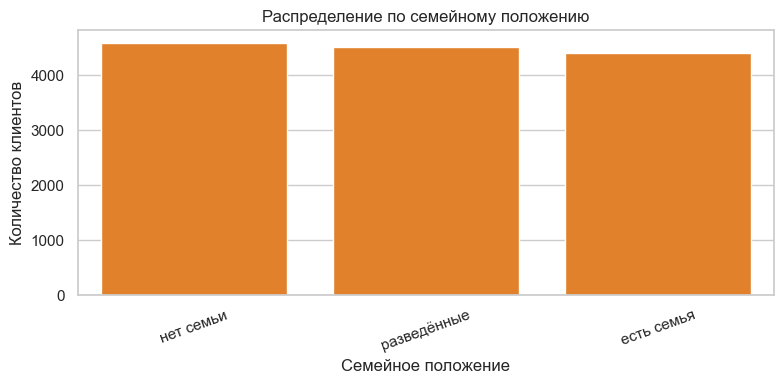

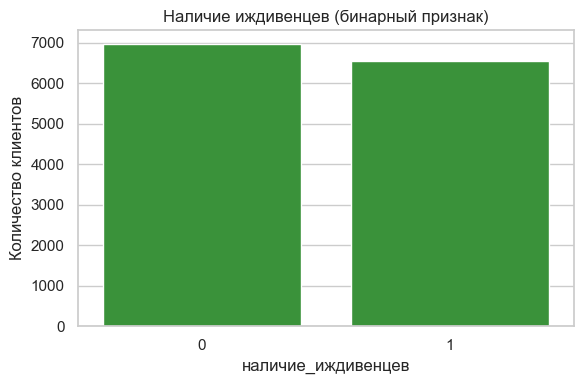

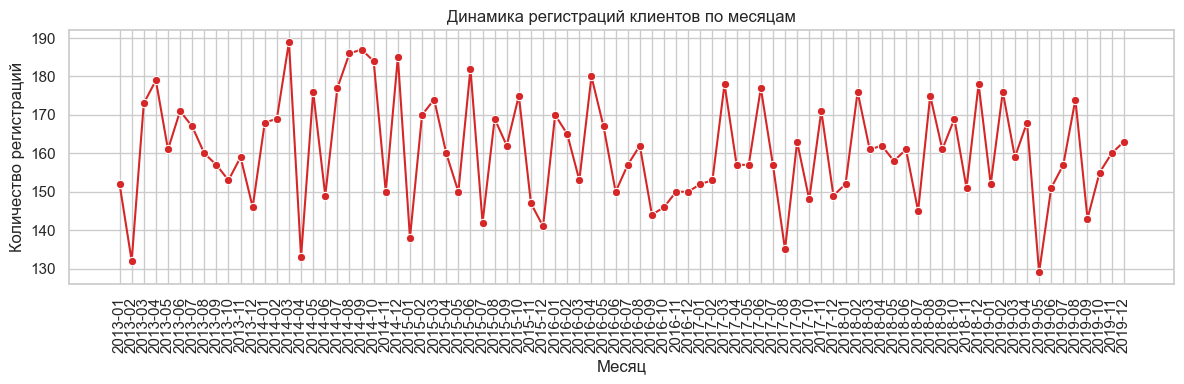

In [8]:
df_client = run_dataset_eda(
    dataset_key="client_description",
    title="Описание клиента",
    date_cols_hint=["дата_регистрации"],
)

if "возраст" in df_client.columns:
    plt.figure(figsize=(10, 4))
    sns.histplot(df_client["возраст"].dropna(), bins=30, kde=True, color="#1f77b4")
    plt.title("Распределение возраста клиентов")
    plt.xlabel("Возраст")
    plt.ylabel("Количество клиентов")
    plt.tight_layout()
    plt.show()

if "семейное_положение" in df_client.columns:
    order_family = df_client["семейное_положение"].astype(str).value_counts().index
    plt.figure(figsize=(8, 4))
    sns.countplot(data=df_client, x="семейное_положение", order=order_family, color="#ff7f0e")
    plt.title("Распределение по семейному положению")
    plt.xlabel("Семейное положение")
    plt.ylabel("Количество клиентов")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

if "наличие_иждивенцев" in df_client.columns:
    order_dep = sorted(df_client["наличие_иждивенцев"].dropna().unique())
    plt.figure(figsize=(6, 4))
    sns.countplot(data=df_client, x="наличие_иждивенцев", order=order_dep, color="#2ca02c")
    plt.title("Наличие иждивенцев (бинарный признак)")
    plt.xlabel("наличие_иждивенцев")
    plt.ylabel("Количество клиентов")
    plt.tight_layout()
    plt.show()

if "дата_регистрации" in df_client.columns:
    df_client["дата_регистрации"] = pd.to_datetime(df_client["дата_регистрации"], errors="coerce")
    reg_monthly = (
        df_client.dropna(subset=["дата_регистрации"])
        .groupby(df_client.dropna(subset=["дата_регистрации"])["дата_регистрации"].dt.to_period("M"))
        .size()
        .sort_index()
    )
    plt.figure(figsize=(12, 4))
    sns.lineplot(x=reg_monthly.index.astype(str), y=reg_monthly.values, marker="o", color="#d62728")
    plt.title("Динамика регистраций клиентов по месяцам")
    plt.xlabel("Месяц")
    plt.ylabel("Количество регистраций")
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.show()

### 3.5 credit_description

EDA: Характеристики кредита (credit_description)
Размер: 13,500 строк x 3 столбцов

Первые 5 строк:


,ID,доход,сумма_кредита
0,IDF55109846,27035,1960785
1,IDF54900291,64502,3375810
2,IDF54995533,90477,401700
3,IDF55065581,133475,1952655
4,IDF55057353,51324,1107870



Типы данных:


,dtype
ID,object
доход,int64
сумма_кредита,int64



Пропуски по столбцам:


,missing_count,missing_share
ID,0,0.0
доход,0,0.0
сумма_кредита,0,0.0



Полных дубликатов: 0 (0.0%)

Описательная статистика числовых признаков:


,count,mean,std,min,25%,50%,75%,max
доход,13500.0,7.908927e+04,4.004555e+04,15010.0,43347.00,77991.5,113615.50,149988.0
сумма_кредита,13500.0,1.993383e+06,1.061381e+06,75000.0,1079328.75,2032732.5,2919236.25,3749400.0


venv/lib/python3.12/site-packages/scipy/_lib/_util.py:1235: RuntimeWarning: divide by zero encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
venv/lib/python3.12/site-packages/scipy/_lib/_util.py:1235: RuntimeWarning: overflow encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
venv/lib/python3.12/site-packages/scipy/_lib/_util.py:1235: RuntimeWarning: invalid value encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
venv/lib/python3.12/site-packages/scipy/_lib/_util.py:1235: RuntimeWarning: divide by zero encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
venv/lib/python3.12/site-packages/scipy/_lib/_util.py:1235: RuntimeWarning: overflow encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
venv/lib/python3.12/site-packages/scipy/_lib/_util.py:1235: RuntimeWarning: invalid value encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)


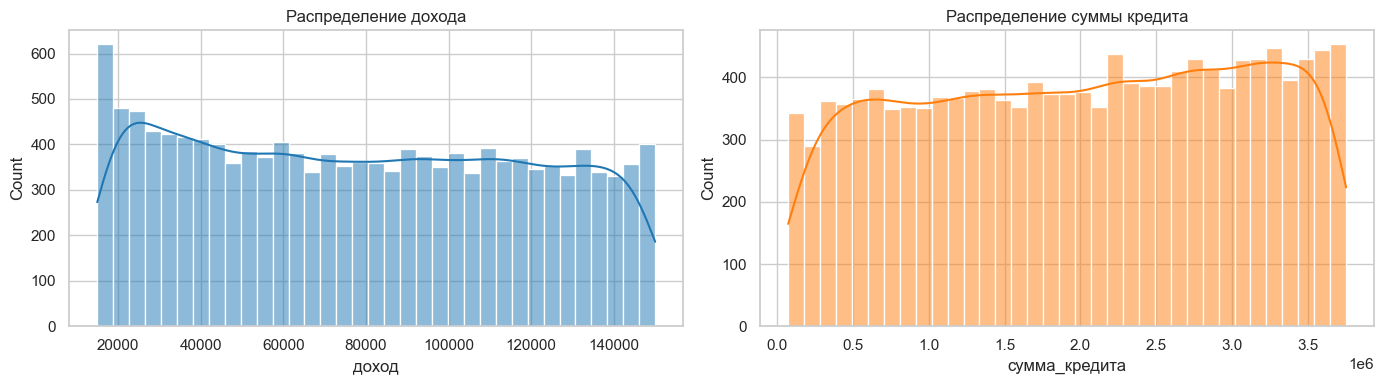

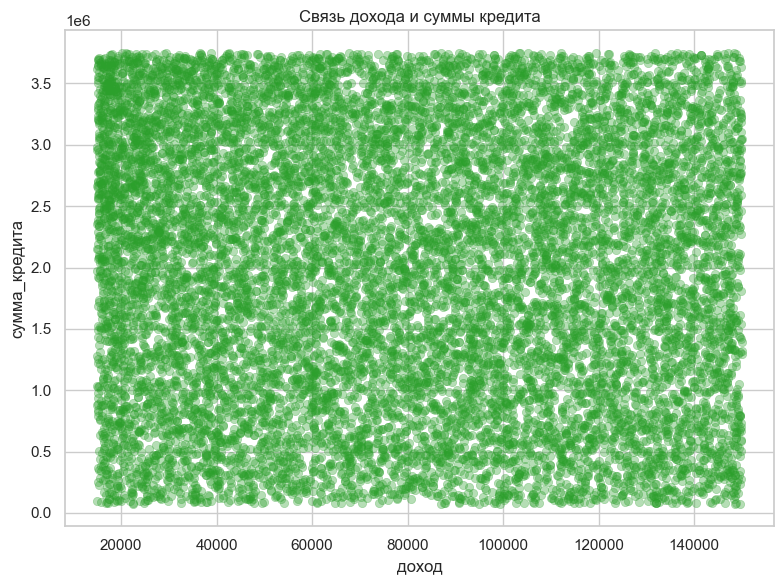

venv/lib/python3.12/site-packages/scipy/_lib/_util.py:1235: RuntimeWarning: divide by zero encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
venv/lib/python3.12/site-packages/scipy/_lib/_util.py:1235: RuntimeWarning: overflow encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
venv/lib/python3.12/site-packages/scipy/_lib/_util.py:1235: RuntimeWarning: invalid value encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)


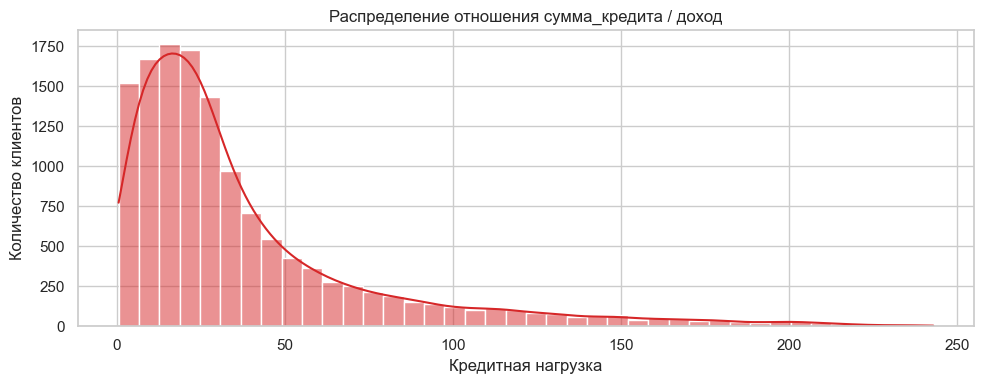

In [9]:
df_credit = run_dataset_eda(
    dataset_key="credit_description",
    title="Характеристики кредита",
)

if {"доход", "сумма_кредита"}.issubset(df_credit.columns):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))

    sns.histplot(df_credit["доход"].dropna(), bins=35, kde=True, ax=axes[0], color="#1f77b4")
    axes[0].set_title("Распределение дохода")
    axes[0].set_xlabel("доход")

    sns.histplot(df_credit["сумма_кредита"].dropna(), bins=35, kde=True, ax=axes[1], color="#ff7f0e")
    axes[1].set_title("Распределение суммы кредита")
    axes[1].set_xlabel("сумма_кредита")

    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(8, 6))
    sns.scatterplot(data=df_credit, x="доход", y="сумма_кредита", alpha=0.35, color="#2ca02c", edgecolor=None)
    plt.title("Связь дохода и суммы кредита")
    plt.xlabel("доход")
    plt.ylabel("сумма_кредита")
    plt.tight_layout()
    plt.show()

    ratio = (df_credit["сумма_кредита"] / df_credit["доход"]).replace([np.inf, -np.inf], np.nan)
    plt.figure(figsize=(10, 4))
    sns.histplot(ratio.dropna(), bins=40, kde=True, color="#d62728")
    plt.title("Распределение отношения сумма_кредита / доход")
    plt.xlabel("Кредитная нагрузка")
    plt.ylabel("Количество клиентов")
    plt.tight_layout()
    plt.show()
else:
    print("Ожидаемые столбцы доход и сумма_кредита не найдены.")

### 3.6 mortgage_presence


EDA: Наличие ипотеки (mortgage_presence)
Размер: 6,609 строк x 3 столбцов

Первые 5 строк:


,ID,дата_открытия,наличие_ипотеки
0,IDF54896351,2013-03-01,1
1,IDF54896367,2018-01-01,1
2,IDF54896414,2018-02-01,1
3,IDF54896494,2019-02-01,1
4,IDF54896615,2018-12-01,1



Типы данных:


,dtype
ID,object
дата_открытия,datetime64[ns]
наличие_ипотеки,int64



Пропуски по столбцам:


,missing_count,missing_share
ID,0,0.0
дата_открытия,0,0.0
наличие_ипотеки,0,0.0



Полных дубликатов: 0 (0.0%)

Описательная статистика числовых признаков:


,count,mean,std,min,25%,50%,75%,max
наличие_ипотеки,6609.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0


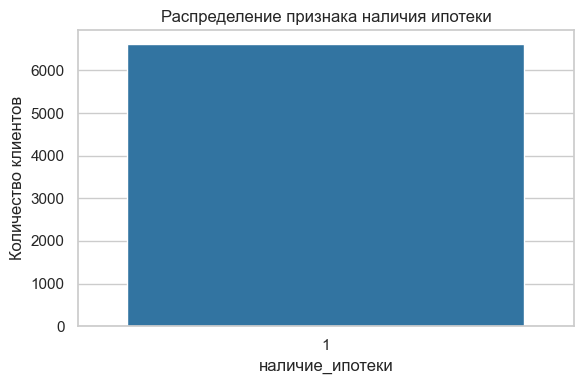

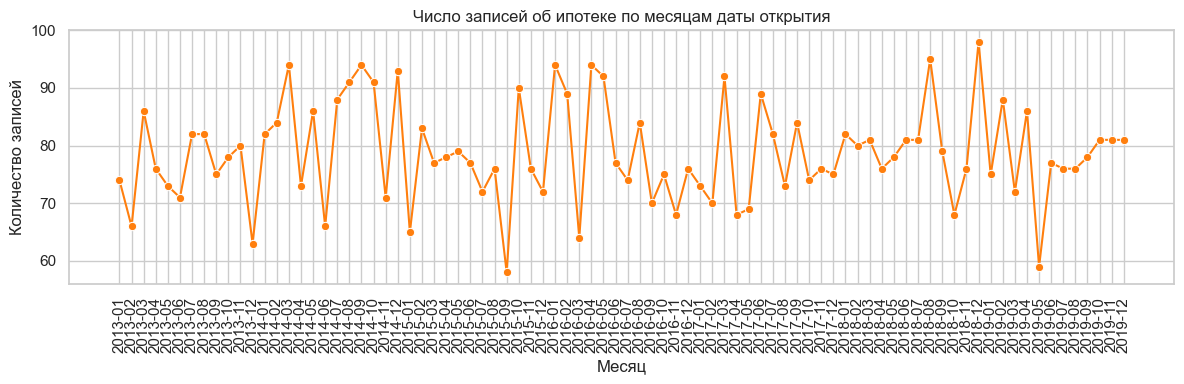

In [10]:
df_mort = run_dataset_eda(
    dataset_key="mortgage_presence",
    title="Наличие ипотеки",
    date_cols_hint=["дата_открытия"],
)

if "наличие_ипотеки" in df_mort.columns:
    order_mort = sorted(df_mort["наличие_ипотеки"].dropna().unique())
    plt.figure(figsize=(6, 4))
    sns.countplot(data=df_mort, x="наличие_ипотеки", order=order_mort, color="#1f77b4")
    plt.title("Распределение признака наличия ипотеки")
    plt.xlabel("наличие_ипотеки")
    plt.ylabel("Количество клиентов")
    plt.tight_layout()
    plt.show()

if "дата_открытия" in df_mort.columns:
    df_mort["дата_открытия"] = pd.to_datetime(df_mort["дата_открытия"], errors="coerce")
    opened_monthly = (
        df_mort.dropna(subset=["дата_открытия"])
        .groupby(df_mort.dropna(subset=["дата_открытия"])["дата_открытия"].dt.to_period("M"))
        .size()
        .sort_index()
    )
    plt.figure(figsize=(12, 4))
    sns.lineplot(x=opened_monthly.index.astype(str), y=opened_monthly.values, marker="o", color="#ff7f0e")
    plt.title("Число записей об ипотеке по месяцам даты открытия")
    plt.xlabel("Месяц")
    plt.ylabel("Количество записей")
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.show()

### 3.7 credit_rating


EDA: Кредитный рейтинг (credit_rating)
Размер: 577,494 строк x 3 столбцов

Первые 5 строк:


,ID,date,кредитный_рейтинг
0,IDF55109846,2013-05-01,692
1,IDF55109846,2013-06-01,688
2,IDF55109846,2013-07-01,666
3,IDF55109846,2013-08-01,692
4,IDF55109846,2013-09-01,688



Типы данных:


,dtype
ID,object
date,datetime64[ns]
кредитный_рейтинг,int64



Пропуски по столбцам:


,missing_count,missing_share
ID,0,0.0
date,0,0.0
кредитный_рейтинг,0,0.0



Полных дубликатов: 0 (0.0%)

Описательная статистика числовых признаков:


,count,mean,std,min,25%,50%,75%,max
кредитный_рейтинг,577494.0,603.190961,64.358896,343.0,558.0,600.0,646.0,900.0


venv/lib/python3.12/site-packages/scipy/_lib/_util.py:1235: RuntimeWarning: divide by zero encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
venv/lib/python3.12/site-packages/scipy/_lib/_util.py:1235: RuntimeWarning: overflow encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
venv/lib/python3.12/site-packages/scipy/_lib/_util.py:1235: RuntimeWarning: invalid value encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)


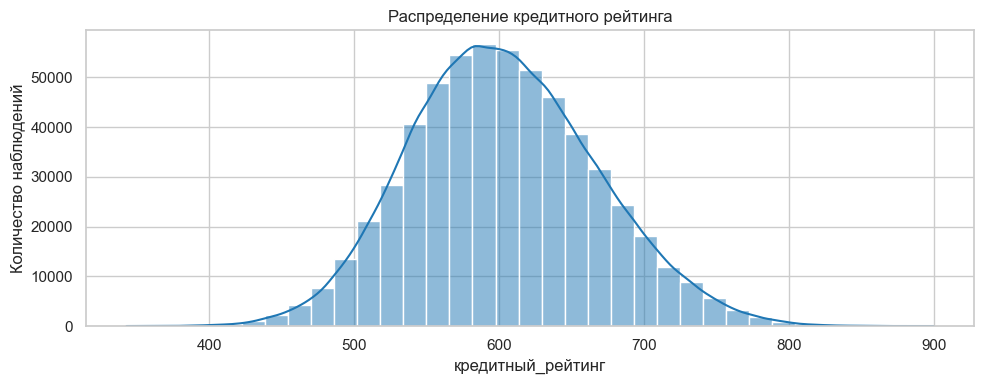

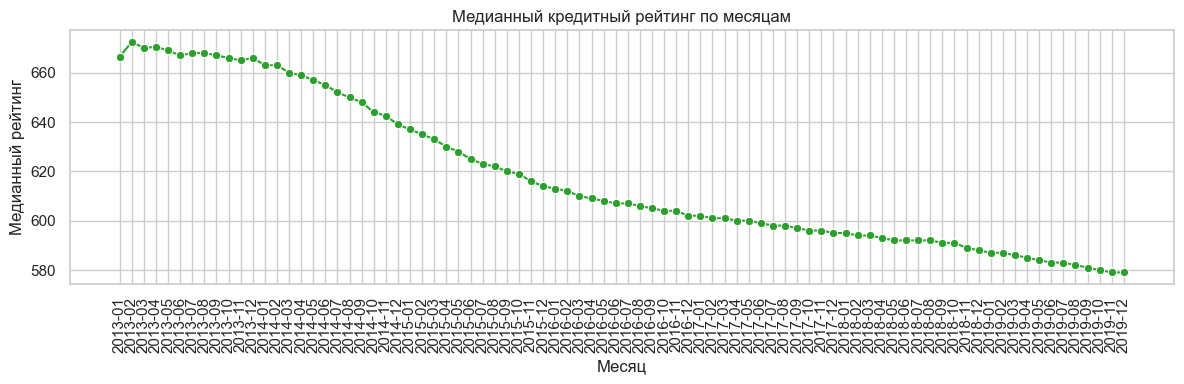

In [11]:
df_rating = run_dataset_eda(
    dataset_key="credit_rating",
    title="Кредитный рейтинг",
    date_cols_hint=["date"],
)

if "кредитный_рейтинг" in df_rating.columns:
    plt.figure(figsize=(10, 4))
    sns.histplot(df_rating["кредитный_рейтинг"].dropna(), bins=35, kde=True, color="#1f77b4")
    plt.title("Распределение кредитного рейтинга")
    plt.xlabel("кредитный_рейтинг")
    plt.ylabel("Количество наблюдений")
    plt.tight_layout()
    plt.show()

if {"date", "кредитный_рейтинг"}.issubset(df_rating.columns):
    df_rating["date"] = pd.to_datetime(df_rating["date"], errors="coerce")
    rating_monthly = (
        df_rating.dropna(subset=["date", "кредитный_рейтинг"])
        .groupby(df_rating.dropna(subset=["date", "кредитный_рейтинг"])["date"].dt.to_period("M"))["кредитный_рейтинг"]
        .median()
        .sort_index()
    )
    plt.figure(figsize=(12, 4))
    sns.lineplot(x=rating_monthly.index.astype(str), y=rating_monthly.values, marker="o", color="#2ca02c")
    plt.title("Медианный кредитный рейтинг по месяцам")
    plt.xlabel("Месяц")
    plt.ylabel("Медианный рейтинг")
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.show()

### 3.8 macro_data


EDA: Макроэкономические данные (macro_data)
Размер: 84 строк x 4 столбцов

Первые 5 строк:


,date,учетная_ставка,уровень_безработицы,инфляция
0,2013-01-01,5.5,5.7,0.97
1,2013-02-01,5.5,5.8,0.56
2,2013-03-01,5.5,5.9,0.34
3,2013-04-01,5.5,5.5,0.51
4,2013-05-01,5.5,5.4,0.66



Типы данных:


,dtype
date,datetime64[ns]
учетная_ставка,float64
уровень_безработицы,float64
инфляция,float64



Пропуски по столбцам:


,missing_count,missing_share
date,0,0.0
учетная_ставка,0,0.0
уровень_безработицы,0,0.0
инфляция,0,0.0



Полных дубликатов: 0 (0.0%)

Описательная статистика числовых признаков:


,count,mean,std,min,25%,50%,75%,max
учетная_ставка,84.0,8.638517,2.466112,5.50,7.2500,7.750,10.329545,17.00
уровень_безработицы,84.0,5.175000,0.409488,4.30,4.9000,5.200,5.500000,6.00
инфляция,84.0,0.527500,0.570189,-0.54,0.2625,0.425,0.635000,3.85


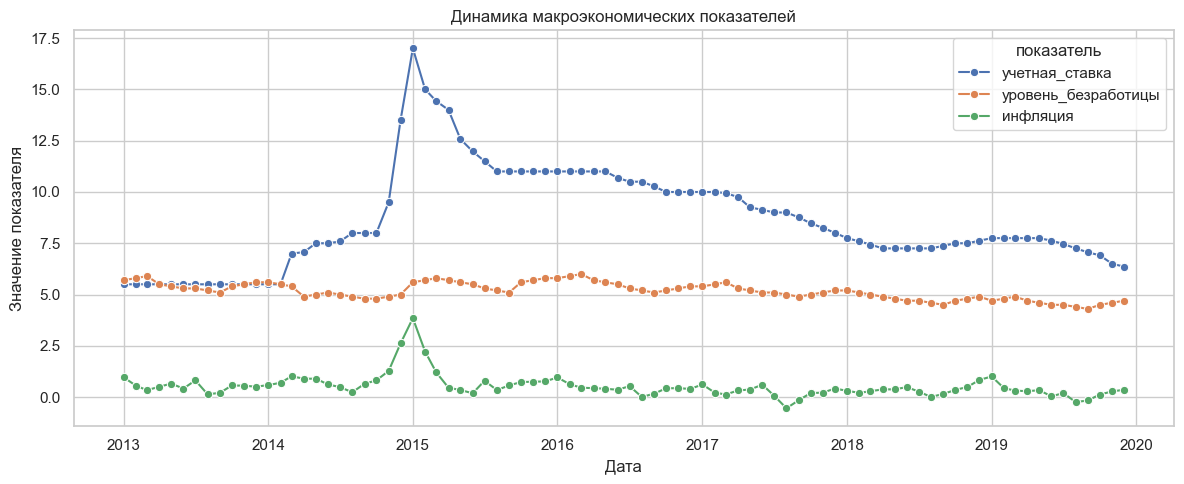

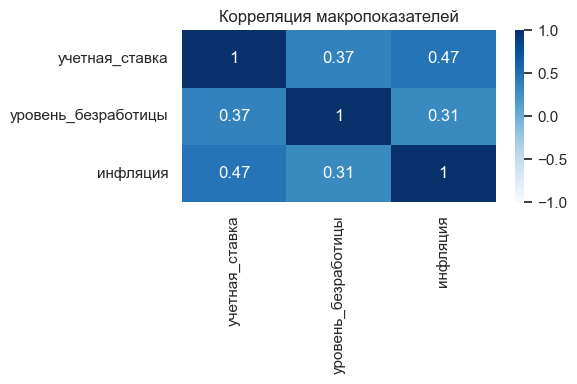

In [12]:
df_macro = run_dataset_eda(
    dataset_key="macro_data",
    title="Макроэкономические данные",
    date_cols_hint=["date"],
)

macro_cols = [c for c in ["учетная_ставка", "уровень_безработицы", "инфляция"] if c in df_macro.columns]
if "date" in df_macro.columns and macro_cols:
    df_macro["date"] = pd.to_datetime(df_macro["date"], errors="coerce")
    macro_plot = df_macro.dropna(subset=["date"] + macro_cols).sort_values("date")

    macro_long = macro_plot.melt(
        id_vars="date",
        value_vars=macro_cols,
        var_name="показатель",
        value_name="значение",
    )

    plt.figure(figsize=(12, 5))
    sns.lineplot(data=macro_long, x="date", y="значение", hue="показатель", marker="o")
    plt.title("Динамика макроэкономических показателей")
    plt.xlabel("Дата")
    plt.ylabel("Значение показателя")
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(6, 4))
    sns.heatmap(macro_plot[macro_cols].corr(), annot=True, cmap="Blues", vmin=-1, vmax=1)
    plt.title("Корреляция макропоказателей")
    plt.tight_layout()
    plt.show()
else:
    print("Для визуализации macro_data не найдены необходимые столбцы date и макропоказатели.")

### 3.9 cohort_grid


EDA: Сетка скоринга (cohort_grid)
Размер: 577,494 строк x 2 столбцов

Первые 5 строк:


,ID,score_date
0,IDF55109846,2013-05-01
1,IDF55109846,2013-06-01
2,IDF55109846,2013-07-01
3,IDF55109846,2013-08-01
4,IDF55109846,2013-09-01



Типы данных:


,dtype
ID,object
score_date,datetime64[ns]



Пропуски по столбцам:


,missing_count,missing_share
ID,0,0.0
score_date,0,0.0



Полных дубликатов: 0 (0.0%)


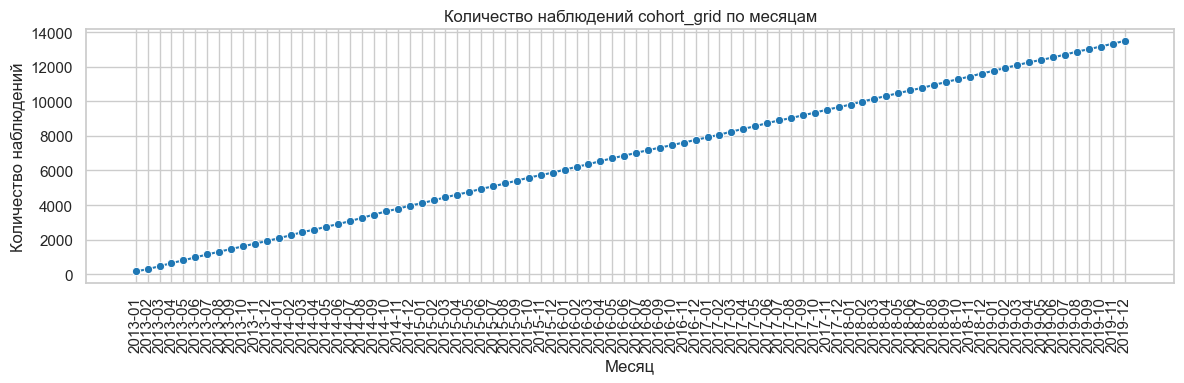

venv/lib/python3.12/site-packages/scipy/_lib/_util.py:1235: RuntimeWarning: divide by zero encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
venv/lib/python3.12/site-packages/scipy/_lib/_util.py:1235: RuntimeWarning: overflow encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
venv/lib/python3.12/site-packages/scipy/_lib/_util.py:1235: RuntimeWarning: invalid value encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)


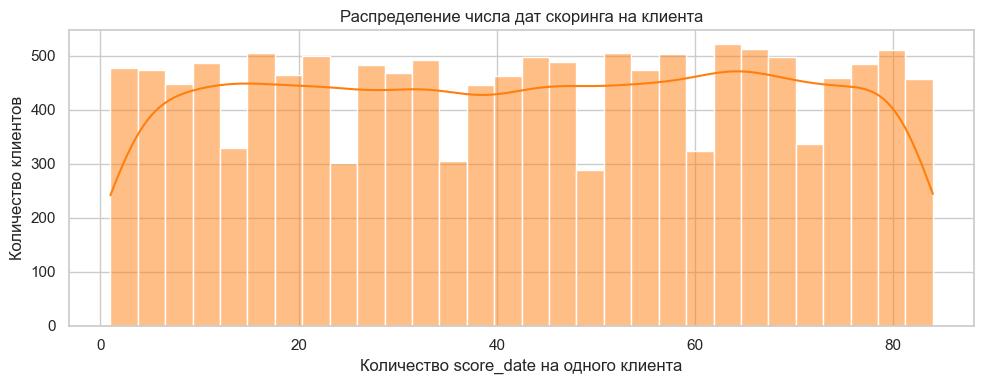

In [13]:
df_cohort = run_dataset_eda(
    dataset_key="cohort_grid",
    title="Сетка скоринга",
    date_cols_hint=["score_date"],
)

if {"ID", "score_date"}.issubset(df_cohort.columns):
    df_cohort["score_date"] = pd.to_datetime(df_cohort["score_date"], errors="coerce")

    cohort_monthly = (
        df_cohort.dropna(subset=["score_date"])
        .groupby(df_cohort.dropna(subset=["score_date"])["score_date"].dt.to_period("M"))
        .size()
        .sort_index()
    )

    plt.figure(figsize=(12, 4))
    sns.lineplot(x=cohort_monthly.index.astype(str), y=cohort_monthly.values, marker="o", color="#1f77b4")
    plt.title("Количество наблюдений cohort_grid по месяцам")
    plt.xlabel("Месяц")
    plt.ylabel("Количество наблюдений")
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.show()

    obs_per_id = df_cohort.groupby("ID").size()
    plt.figure(figsize=(10, 4))
    sns.histplot(obs_per_id, bins=30, kde=True, color="#ff7f0e")
    plt.title("Распределение числа дат скоринга на клиента")
    plt.xlabel("Количество score_date на одного клиента")
    plt.ylabel("Количество клиентов")
    plt.tight_layout()
    plt.show()

else:
    print("Ожидаемые столбцы ID и score_date не найдены в cohort_grid.")


#### Результаты исследовательского анализа данных:

На основе проведённого исследовательского анализа данных получены следующие ключевые результаты по каждому датасету:

**1. loan_payment_credit (просрочки по кредитам)**
- Датасет содержит 5.500 записей о просрочках
- Длительность просрочки варьируется: медиана составляет несколько десятков дней
- Данные не содержат пропусков и готовы к использованию

**2. transactions (транзакции по MCC)**
- 577.494 записей о месячных транзакциях клиентов
- Основные категории расходов: MCC_5411 (средние траты ~9.263 руб.), MCC_5300 (~6.177 руб.), MCC_другое (~5.415 руб.)
- Медианные суммарные ежемесячные траты клиента: ~37-39 тыс. руб. с нисходящим трендом от 2013 к 2019 году
- Полная заполненность данных по всем MCC-кодам

**3. client_description (описание клиента)**
- 13.500 уникальных клиентов в датасете
- Возраст клиентов распределён равномерно в диапазоне рабочих возрастов
- Наличие иждивенцев: примерно 50/50 распределение между клиентами с иждивенцами и без
- Регистрация клиентов неравномерно распределена по месяцам периода 2013-2019
- Нет пропусков в данных

**4. credit_description (характеристики кредита)**
- 13.500 записей (по одной на клиента)
- Доход клиентов: средний уровень ~60-80 тыс. руб./месяц, а средний уровень кредита - 2 млн. руб.
- Полная заполненность данных без пропусков

**5. mortgage_presence (наличие ипотеки)**
- 6.609 клиентов имеют ипотеку (примерно 49% от общей выборки)
- Даты открытия ипотеки равномерно распределены с 2013 по 2019 год (~70-100 ипотек/месяц)
- Нет пропусков в данных

**6. credit_rating (кредитный рейтинг)**
- Рейтинги клиентов варьируются от 343 до 900 баллов
- Медианный рейтинг на период анализа: ~595-600 баллов
- Долгосрочный тренд: снижение среднего рейтинга на протяжении периода 2013-2019
- Полная заполненность данных

**7. macro_data (макроэкономические показатели)**
- Данные по месяцам за период 2013-2019
- Инфляция и учётная ставка демонстрируют волатильность, особенно в периоды 2014-2015 и 2018-2019
- Полная заполненность макроэкономических показателей

**8. cohort_grid (сетка скоринга)**
- 577.494 наблюдений (пары «клиент–дата скоринга»)
- 13.500 уникальных клиентов с множественными датами скоринга (от 1 до 82 дат на клиента)
- Даты скоринга равномерно распределены по месяцам периода 2013-2019
- Полная заполненность данных

**Общие выводы:**
- Все датасеты содержат полные данные без пропусков на первичном уровне
- Периоды покрытия данных согласованы (2013-2019 годы)
- Данные готовы к объединению с учётом временной структуры
- Поведенческие признаки (расходы, рейтинги) показывают нисходящие тренды в период 2018-2019, что может указывать на ухудшение экономической ситуации

---

## 4. Объединение таблиц

### 4.1 Формирование целевой переменной

In [14]:
# --- Формирование целевой переменной ---
def _get_dataset_copy(dataset_key: str) -> pd.DataFrame:
    if "ensure_dataset_loaded" in globals():
        return ensure_dataset_loaded(dataset_key).copy()
    if "datasets" in globals() and dataset_key in datasets:
        return datasets[dataset_key].copy()
    raise KeyError(
        f"Датасет '{dataset_key}' не найден. "
        "Сначала выполните клетки загрузки данных."
    )

cohort = _get_dataset_copy("cohort_grid")
loan = _get_dataset_copy("loan_payment_credit")

cohort["score_date"] = pd.to_datetime(cohort["score_date"], errors="coerce")
loan["дата_начала_периода"] = pd.to_datetime(loan["дата_начала_периода"], errors="coerce")
loan["просрочка_дней"] = pd.to_numeric(loan["просрочка_дней"], errors="coerce")

defaults_90 = loan[loan['просрочка_дней'] >= 90].copy()

# Берем только первую запись клиента с просрочкой от 90 дней
first_defaults_90 = (defaults_90
                     .sort_values('дата_начала_периода')
                     .groupby('ID')
                     .first()
                     .reset_index())

df = cohort.merge(first_defaults_90, on="ID", how="left")

df['is_default'] = (
    df['дата_начала_периода'].notna() & # просрочка есть
    (df['дата_начала_периода'] >= df['score_date']) & # просрочка началась после даты скоринга
    (df['дата_начала_периода'] < df['score_date'] + pd.Timedelta(days=365)) # началась в течение года после скоринга
)

# Удаляем просрочки, которые начались до даты скоринга
mask_delete = (
    df['дата_начала_периода'].notna() &
    (df['дата_начала_периода'] < df['score_date'])
)
df = df[~mask_delete].reset_index(drop=True)


In [15]:
mask_target_0 = df['is_default'] == 0

# Очищаем поля с информацией о будущих просрочках
df.loc[mask_target_0, 'дата_начала_периода'] = None
df.loc[mask_target_0, 'просрочка_дней'] = None

In [16]:
# Проверка строк с просрочками в прошлом
display((df[(df['is_default'] == 1) & (df['дата_начала_периода'] < df['score_date'])]))
display(df.info())

,ID,score_date,дата_начала_периода,просрочка_дней,is_default


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 438379 entries, 0 to 438378
Data columns (total 5 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   ID                   438379 non-null  object        
 1   score_date           438379 non-null  datetime64[ns]
 2   дата_начала_периода  49364 non-null   datetime64[ns]
 3   просрочка_дней       49364 non-null   float64       
 4   is_default           438379 non-null  bool          
dtypes: bool(1), datetime64[ns](2), float64(1), object(1)
memory usage: 13.8+ MB


None

In [17]:
print(f"Размер итогового датасета для моделирования: {df.shape[0]:,} строк x {df.shape[1]:,} столбцов")
print("\nРаспределение целевой переменной 'is_default':")
print(df['is_default'].value_counts().to_frame("count").assign(share=lambda x: (x["count"] / len(df) * 100).round(2)))

Размер итогового датасета для моделирования: 438,379 строк x 5 столбцов

Распределение целевой переменной 'is_default':
             count  share
is_default               
False       389015  88.74
True         49364  11.26


### 4.2 Формирование итоговой таблицы

In [18]:
transactins_df = _get_dataset_copy("transactions")
credit_rating_df = _get_dataset_copy("credit_rating")
macro_data_df = _get_dataset_copy("macro_data")
clients_df = _get_dataset_copy("client_description")
credit_df = _get_dataset_copy("credit_description")
mortgage_df = _get_dataset_copy("mortgage_presence")

transactins_df["date"] = pd.to_datetime(transactins_df["date"], errors="coerce")
credit_rating_df["date"] = pd.to_datetime(credit_rating_df["date"], errors="coerce")
macro_data_df["date"] = pd.to_datetime(macro_data_df["date"], errors="coerce")
clients_df["дата_регистрации"] = pd.to_datetime(clients_df["дата_регистрации"], errors="coerce")
mortgage_df["дата_открытия"] = pd.to_datetime(mortgage_df["дата_открытия"], errors="coerce")

# Не позднее предыдущего месяца для исключения утечки данных из будущего
df['prev_month_date'] = df['score_date'] - pd.DateOffset(months=1)

# Транзакции по ID и дате скоринга
df = df.merge(
    transactins_df, 
    left_on=["ID", "prev_month_date"],
    right_on=["ID", "date"],
    how="left",
)

# Рейтинг по ID и дате скоринга
df = df.merge(
    credit_rating_df,
    left_on=["ID", "prev_month_date"],
    right_on=["ID", "date"],
    how="left",
    suffixes=("_trans", "_rating")
)

# Макро по дате скоринга
df = df.merge(
    macro_data_df,
    left_on="prev_month_date",
    right_on="date",
    how="left",
)

# Описание клиента, кредита и наличие ипотеки по ID
df = df.merge(clients_df, on="ID", how="left")
df = df.merge(credit_df, on="ID", how="left")
df = df.merge(mortgage_df, on="ID", how="left")


In [19]:
# Если ипотека открыта после скоринга, удаляем информацию из несоответствующих строк
mask_future_mortgage = df['дата_открытия'] > df['score_date']
df.loc[mask_future_mortgage, 'наличие_ипотеки'] = 0
df.loc[mask_future_mortgage, 'дата_открытия'] = None

# Заполняем пропуски у клиентов без ипотеки и без просрочки, так как эти признаки могут быть не применимы к ним
df['наличие_ипотеки'] = df['наличие_ипотеки'].fillna(0)

# Проверка
display(df[(df['score_date'] < df['дата_открытия'])])

,ID,score_date,дата_начала_периода,просрочка_дней,is_default,prev_month_date,date_trans,MCC_5300,MCC_5814,MCC_5812,MCC_5411,MCC_3990,MCC_5722,MCC_4900,MCC_другое,date_rating,кредитный_рейтинг,date,учетная_ставка,уровень_безработицы,инфляция,возраст,семейное_положение,наличие_иждивенцев,дата_регистрации,доход,сумма_кредита,дата_открытия,наличие_ипотеки


In [20]:
# Удаляем строки, где невозможно проверить полный горизонт 365 дней
# Находим максимальную дату дефолта в датасете
max_default_date = df['дата_начала_периода'].max()

# Оставляем только строки, где score_date + 365 дней не выходит за пределы наблюдения
df = df[df['score_date'] + pd.Timedelta(days=365) <= max_default_date].copy()

print(f"Размер датасета после удаления строк без полного горизонта: {df.shape[0]:,}")
print(f"Новый диапазон дат: {df['score_date'].min()} - {df['score_date'].max()}")

Размер датасета после удаления строк без полного горизонта: 334,696
Новый диапазон дат: 2013-01-01 00:00:00 - 2018-12-01 00:00:00


In [21]:
# Удаляем лишние колонки с датами
cols_to_drop = [
    'date',
    'date_rating',
    'date_trans',
    'дата_открытия',
    'просрочка_дней',
    'prev_month_date'
]
df = df.drop(columns=[c for c in cols_to_drop if c in df.columns], errors="ignore")

print(f"Итоговая таблица собрана, размер: {df.shape[0]:,} строк x {df.shape[1]:,} столбцов")
display(df.head())

print(f'Пропуски в итоговой таблице: {df.isnull().sum()}')

Итоговая таблица собрана, размер: 334,696 строк x 23 столбцов


,ID,score_date,дата_начала_периода,is_default,MCC_5300,MCC_5814,MCC_5812,MCC_5411,MCC_3990,MCC_5722,MCC_4900,MCC_другое,кредитный_рейтинг,учетная_ставка,уровень_безработицы,инфляция,возраст,семейное_положение,наличие_иждивенцев,дата_регистрации,доход,сумма_кредита,наличие_ипотеки
0,IDF55109846,2013-05-01,NaT,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.5,5.5,0.51,41,разведённые,1,2013-05-01,27035,1960785,0.0
1,IDF55109846,2013-06-01,NaT,False,3267.59,1282.11,1457.96,5711.10,647.43,2374.78,4059.86,3657.35,692.0,5.5,5.4,0.66,41,разведённые,1,2013-05-01,27035,1960785,0.0
2,IDF55109846,2013-07-01,NaT,False,3196.58,2443.37,1334.20,5824.65,1067.55,2187.11,4592.26,3322.61,688.0,5.5,5.3,0.42,41,разведённые,1,2013-05-01,27035,1960785,0.0
3,IDF55109846,2013-08-01,NaT,False,3550.54,4277.72,1463.75,5209.51,1167.95,2076.54,3605.25,3467.06,666.0,5.5,5.3,0.82,41,разведённые,1,2013-05-01,27035,1960785,0.0
4,IDF55109846,2013-09-01,NaT,False,3385.98,4530.63,1261.40,5765.96,986.99,2231.77,2209.39,3354.44,692.0,5.5,5.2,0.14,41,разведённые,1,2013-05-01,27035,1960785,0.0


Пропуски в итоговой таблице: ID                          0
score_date                  0
дата_начала_периода    290332
is_default                  0
MCC_5300                11613
MCC_5814                11613
MCC_5812                11613
MCC_5411                11613
MCC_3990                11613
MCC_5722                11613
MCC_4900                11613
MCC_другое              11613
кредитный_рейтинг       11613
учетная_ставка            152
уровень_безработицы       152
инфляция                  152
возраст                     0
семейное_положение          0
наличие_иждивенцев          0
дата_регистрации            0
доход                       0
сумма_кредита               0
наличие_ипотеки             0
dtype: int64


In [22]:
# Выбираем случайного клиента, у которого много записей и таргет 1
example_id = df[df['is_default'] == 1]['ID'].value_counts().idxmax()

print(f"Пример клиента с ID={example_id}, у которого много записей с таргетом 1:")

# Сортируем по дате скоринга и сбрасываем индекс для удобства просмотра
display(df[df['ID'] == example_id].sort_values("score_date").reset_index(drop=True))

Пример клиента с ID=IDF55109846, у которого много записей с таргетом 1:


,ID,score_date,дата_начала_периода,is_default,MCC_5300,MCC_5814,MCC_5812,MCC_5411,MCC_3990,MCC_5722,MCC_4900,MCC_другое,кредитный_рейтинг,учетная_ставка,уровень_безработицы,инфляция,возраст,семейное_положение,наличие_иждивенцев,дата_регистрации,доход,сумма_кредита,наличие_ипотеки
0,IDF55109846,2013-05-01,NaT,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.500000,5.5,0.51,41,разведённые,1,2013-05-01,27035,1960785,0.0
1,IDF55109846,2013-06-01,NaT,False,3267.59,1282.11,1457.96,5711.10,647.43,2374.78,4059.86,3657.35,692.0,5.500000,5.4,0.66,41,разведённые,1,2013-05-01,27035,1960785,0.0
2,IDF55109846,2013-07-01,NaT,False,3196.58,2443.37,1334.20,5824.65,1067.55,2187.11,4592.26,3322.61,688.0,5.500000,5.3,0.42,41,разведённые,1,2013-05-01,27035,1960785,0.0
3,IDF55109846,2013-08-01,NaT,False,3550.54,4277.72,1463.75,5209.51,1167.95,2076.54,3605.25,3467.06,666.0,5.500000,5.3,0.82,41,разведённые,1,2013-05-01,27035,1960785,0.0
4,IDF55109846,2013-09-01,NaT,False,3385.98,4530.63,1261.40,5765.96,986.99,2231.77,2209.39,3354.44,692.0,5.500000,5.2,0.14,41,разведённые,1,2013-05-01,27035,1960785,0.0
5,IDF55109846,2013-10-01,NaT,False,3214.84,4146.65,1405.15,5632.11,640.76,2156.67,1519.46,4352.90,688.0,5.500000,5.1,0.21,41,разведённые,1,2013-05-01,27035,1960785,0.0
6,IDF55109846,2013-11-01,NaT,False,3403.35,2712.24,2376.85,7787.57,633.10,2210.14,1582.11,5204.70,669.0,5.500000,5.4,0.57,41,разведённые,1,2013-05-01,27035,1960785,0.0
7,IDF55109846,2013-12-01,NaT,False,4500.41,1135.50,3904.15,8539.47,673.48,2054.81,1398.36,4209.13,658.0,5.500000,5.5,0.56,41,разведённые,1,2013-05-01,27035,1960785,0.0
8,IDF55109846,2014-01-01,2014-12-01,True,7200.15,1265.92,4378.75,8504.99,680.99,2401.45,1748.05,3656.03,656.0,5.500000,5.6,0.51,41,разведённые,1,2013-05-01,27035,1960785,0.0
9,IDF55109846,2014-02-01,2014-12-01,True,7873.01,1366.63,3940.49,6842.59,732.78,2359.89,1828.13,3791.34,655.0,5.500000,5.6,0.59,41,разведённые,1,2013-05-01,27035,1960785,0.0


In [23]:
# Финальные проверки
print(f'Количество дубликатов: {df.duplicated(["ID", "score_date"]).sum()}')
print(f'Средняя вероятность дефолта по датам: {df.groupby("score_date")["is_default"].mean().round(4).tolist()}')

Количество дубликатов: 0
Средняя вероятность дефолта по датам: [0.0658, 0.0845, 0.105, 0.1116, 0.123, 0.1477, 0.1648, 0.1753, 0.1963, 0.2224, 0.2404, 0.248, 0.2449, 0.2482, 0.2434, 0.2459, 0.2433, 0.2412, 0.2318, 0.2246, 0.2138, 0.2053, 0.1987, 0.1943, 0.1892, 0.1828, 0.1768, 0.1709, 0.1686, 0.1659, 0.1629, 0.1605, 0.1565, 0.1492, 0.1455, 0.1421, 0.1393, 0.1334, 0.1321, 0.1279, 0.1241, 0.121, 0.1186, 0.115, 0.1153, 0.1125, 0.1105, 0.1077, 0.1078, 0.1062, 0.104, 0.1009, 0.0982, 0.0956, 0.0939, 0.096, 0.0963, 0.0994, 0.1019, 0.1089, 0.1191, 0.119, 0.1191, 0.1194, 0.1175, 0.1154, 0.1131, 0.1105, 0.1069, 0.1031, 0.0989, 0.0915]


#### Выводы по формирониваю целевой переменной и итоговой таблице

- В качестве основы использована таблица `cohort_grid` с парами `ID` и `score_date`.
- Целевая переменная `is_default` была задана как `1`, если у клиента был первый эпизод просрочки `>= 90` дней в интервале от `score_date` до `score_date + 365 дней`.
- Если дефолт уже произошёл до даты скоринга, такие строки исключались, чтобы не допустить утечку информации из прошлого.
- Итоговая таблица собрана объединением `cohort_grid` с:
    - просрочками по кредитам;
    - транзакциями;
    - кредитным рейтингом;
    - макроэкономическими показателями;
    - описанием клиента;
    - характеристиками кредита;
    - данными об ипотеке.
- При объединении учитывалась временная структура: использовались только признаки, которые могли быть известны на дату скоринга или раньше.
- В результате получена большая витрина наблюдений «клиент–дата скоринга» с целевым признаком для обучения модели.

---

## 5. Создание новых признаков

In [24]:
# --- Создание новых признаков ---
df = df.copy()

# Поведенческие признаки по транзакциям
mcc_cols = [c for c in df.columns if c.startswith("MCC_")]
if mcc_cols:
    df["total_mcc_spend"] = df[mcc_cols].sum(axis=1)
    df["mcc_spend_std"] = df[mcc_cols].std(axis=1)
    mcc_values = df[mcc_cols].to_numpy()
    top_idx = mcc_values.argmax(axis=1)
    top_vals = mcc_values[np.arange(len(df)), top_idx]
    df["top_mcc_share"] = top_vals / df["total_mcc_spend"].replace(0, np.nan)
    df["top_mcc_share"] = df["top_mcc_share"].fillna(0)
    if "MCC_4900" in df.columns:
        df["share_utilities"] = df["MCC_4900"] / df["total_mcc_spend"].replace(0, np.nan)
        df["share_utilities"] = df["share_utilities"].fillna(0)

# Финансовые и демографические признаки
if {"доход", "сумма_кредита"}.issubset(df.columns):
    df["credit_to_income"] = df["сумма_кредита"] / df["доход"].replace(0, np.nan)
    df["credit_to_income"] = df["credit_to_income"].replace([np.inf, -np.inf], np.nan)
    df["income_log"] = np.log1p(df["доход"].clip(lower=0))

# Стаж клиента в банке на дату скоринга
if {"дата_регистрации", "score_date"}.issubset(df.columns):
    df["tenure_months"] = (
        (df["score_date"] - df["дата_регистрации"]).dt.days / 30.0
    ).clip(lower=0)

# Инфляционные признаки и реальный доход
if {"инфляция", "score_date"}.issubset(df.columns) and "macro_data_df" in globals():
    df_macro_sorted = macro_data_df.sort_values("date").copy()
    df_macro_sorted["inflation_factor"] = 1 + df_macro_sorted["инфляция"] / 100
    df_macro_sorted["cpi_index"] = df_macro_sorted["inflation_factor"].cumprod()
    df_macro_sorted["inflation_delta_1m"] = df_macro_sorted["инфляция"].diff()
    df_macro_sorted["inflation_delta_3m"] = df_macro_sorted["инфляция"].diff(3)
    df = df.merge(
        df_macro_sorted[["date", "cpi_index", "inflation_delta_1m", "inflation_delta_3m"]],
        left_on="score_date",
        right_on="date",
        how="left",
    )
    df = df.drop(columns=["date"], errors="ignore")

    if "доход" in df.columns:
        df["real_income_cumulative"] = df["доход"] / df["cpi_index"]

# Динамика кредитного рейтинга
if {"ID", "кредитный_рейтинг"}.issubset(df.columns):
    df["rating_change_1m"] = df.groupby("ID")["кредитный_рейтинг"].diff(1)
    df["rating_change_3m"] = df.groupby("ID")["кредитный_рейтинг"].diff(3)

# Тренд расходов
if {"ID", "total_mcc_spend"}.issubset(df.columns):
    df["avg_spend_3m_lag"] = (
        df.groupby("ID")["total_mcc_spend"]
          .transform(lambda s: s.shift(1).rolling(3).mean())
    )
    df["spend_trend"] = df["total_mcc_spend"] / (df["avg_spend_3m_lag"] + 1)

# Заполняем пропуски в новых признаках
cols_to_fill = [
    "inflation_delta_1m",
    "inflation_delta_3m",
    "rating_change_1m",
    "rating_change_3m",
    "spend_trend",
    "avg_spend_3m_lag",
]
for col in cols_to_fill:
    if col in df.columns:
        df[col] = df[col].fillna(0)

new_features = [
    "total_mcc_spend",
    "mcc_spend_std",
    "top_mcc_share",
    "share_utilities",
    "credit_to_income",
    "income_log",
    "tenure_months",
    "cpi_index",
    "inflation_delta_1m",
    "inflation_delta_3m",
    "real_income_cumulative",
    "rating_change_1m",
    "rating_change_3m",
    "avg_spend_3m_lag",
    "spend_trend"
]

available_new = [c for c in new_features if c in df.columns]
print(f"Создано новых признаков: {len(available_new)}")
print("Список новых признаков:")
print(available_new)
display(df[available_new].head())

Создано новых признаков: 15
Список новых признаков:
['total_mcc_spend', 'mcc_spend_std', 'top_mcc_share', 'share_utilities', 'credit_to_income', 'income_log', 'tenure_months', 'cpi_index', 'inflation_delta_1m', 'inflation_delta_3m', 'real_income_cumulative', 'rating_change_1m', 'rating_change_3m', 'avg_spend_3m_lag', 'spend_trend']


,total_mcc_spend,mcc_spend_std,top_mcc_share,share_utilities,credit_to_income,income_log,tenure_months,cpi_index,inflation_delta_1m,inflation_delta_3m,real_income_cumulative,rating_change_1m,rating_change_3m,avg_spend_3m_lag,spend_trend
0,0.00,NaN,0.000000,0.000000,72.527649,10.204925,0.000000,1.030761,0.15,0.10,26228.198222,0.0,0.0,0.000000,0.000000
1,22458.18,1687.536150,0.254299,0.180774,72.527649,10.204925,1.033333,1.035090,-0.24,0.08,26118.500520,0.0,0.0,0.000000,0.000000
2,23968.33,1609.632381,0.243014,0.191597,72.527649,10.204925,2.033333,1.043578,0.40,0.31,25906.070740,-4.0,0.0,0.000000,0.000000
3,24818.32,1408.525745,0.209906,0.145266,72.527649,10.204925,3.066667,1.045039,-0.68,-0.52,25869.852946,-22.0,0.0,15475.503333,1.603613
4,23726.56,1627.829657,0.243017,0.093119,72.527649,10.204925,4.100000,1.047233,0.07,-0.21,25815.640102,26.0,0.0,23748.276667,0.999043


#### Описание новых признаков

- total_mcc_spend — суммарные ежемесячные траты по MCC. Отражает уровень расходной активности; низкие/резко падающие траты могут предшествовать дефолту, а очень высокие — сигнал кредитной нагрузки.

- mcc_spend_std — стандартное отклонение трат по MCC. Высокая дисперсия может указывать на нерегулярные/аврал‑траты, связанные с ухудшением платежеспособности.

- top_mcc_share — доля самой крупной категории расходов в сумме трат. Большая концентрация расходов может свидетельствовать о структуре потребления и риске (меньшая гибкость бюджета).

- share_utilities — доля коммунальных платежей (MCC_4900) в траттах. Рост доли обязательных платежей уменьшает доступный доход и повышает риск дефолта.

- credit_to_income — отношение суммы кредита к доходу. Классический индикатор кредитной нагрузки; чем выше, тем выше вероятность дефолта.

- income_log — логарифм дохода. Нормализация распределения дохода для стабильного использования в моделях; более низкий лог‑доход обычно связан с повышенным риском.

- tenure_months — стаж отношений с банком в месяцах на дату скоринга. Более короткий стаж = меньше истории и, часто, выше риск; долгий стаж может быть защитным фактором.

- cpi_index — накопительный индекс инфляции (CPI) на дату скоринга. Используется для приведения дохода/платежей к реальному выражению; макроэкономические изменения влияют на массовую вероятность дефолта.

- inflation_delta_1m / inflation_delta_3m — изменение инфляции за 1 / 3 месяца. Резкие изменения макроусловий могут предшествовать росту дефолтов.

- real_income_cumulative — доход, скорректированный на CPI. Лучше отражает реальную покупательную способность и способность обслуживать долг.

- rating_change_1m / rating_change_3m — дельты кредитного рейтинга за 1 / 3 месяца. Падение рейтинга прямо коррелирует с ухудшением кредитоспособности.

- avg_spend_3m_lag — средние траты за предыдущие 3 месяца (лаг). Показывает недавний уровень расходов, используемый для построения трендов и сравнения с текущими тратами.

- spend_trend — отношение текущих трат к среднему за 3‑мес. лаг. Положительная/отрицательная тенденция расходов помогает выявлять ухудшение финансового состояния.

---

## 6. Анализ итоговой таблицы

Размер итоговой таблицы: (334696, 38)

Дисбаланс классов:


,is_default,count,share
0,True,44364,13.26
1,False,290332,86.74


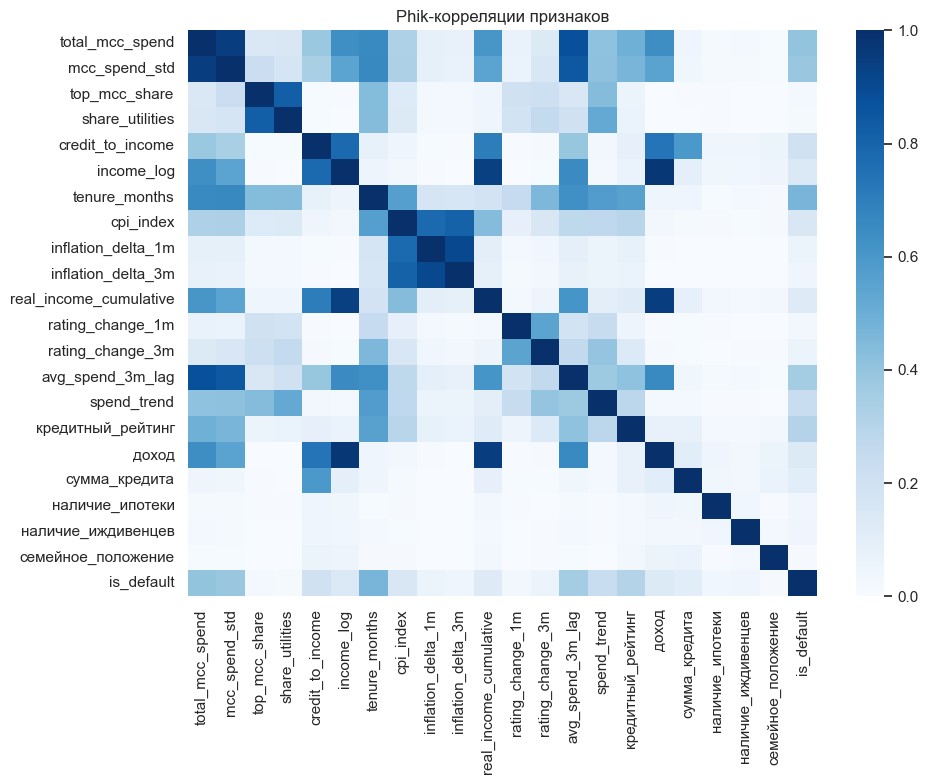


Топ признаков по phik-корреляции с таргетом:


,feature,phik
0,tenure_months,0.465732
1,total_mcc_spend,0.405965
2,mcc_spend_std,0.390354
3,avg_spend_3m_lag,0.356336
4,кредитный_рейтинг,0.308262
5,spend_trend,0.236177
6,credit_to_income,0.200441
7,cpi_index,0.153239
8,income_log,0.142741
9,доход,0.134860


In [25]:
target_col = "is_default"

print("Размер итоговой таблицы:", df.shape)
print("\nДисбаланс классов:")
display(
    df[target_col]
    .value_counts()
    .to_frame("count")
    .assign(share=lambda x: (x["count"] / len(df) * 100).round(2))
    .rename_axis(target_col)
    .reset_index()
    .sort_values(target_col, ascending=False)
    .reset_index(drop=True)
 )

analysis_features = [
    "total_mcc_spend",
    "mcc_spend_std",
    "top_mcc_share",
    "share_utilities",
    "credit_to_income",
    "income_log",
    "tenure_months",
    "cpi_index",
    "inflation_delta_1m",
    "inflation_delta_3m",
    "real_income_cumulative",
    "rating_change_1m",
    "rating_change_3m",
    "avg_spend_3m_lag",
    "spend_trend",
    "кредитный_рейтинг",
    "доход",
    "сумма_кредита",
    "наличие_ипотеки",
    "наличие_иждивенцев",
    "семейное_положение",
]

# Корреляционная матрица phik и топ факторов
phik_cols = [c for c in analysis_features if c != target_col] + [target_col]
phik_cols = [c for c in phik_cols if c in df.columns]
if len(phik_cols) > 2:
    interval_cols = [c for c in phik_cols if pd.api.types.is_numeric_dtype(df[c]) and c != target_col]
    phik_matrix = df[phik_cols].phik_matrix(interval_cols=interval_cols)
    plt.figure(figsize=(10, 8))
    sns.heatmap(phik_matrix, cmap="Blues", vmin=0, vmax=1)
    plt.title("Phik-корреляции признаков")
    plt.tight_layout()
    plt.show()

    phik_target = (
        phik_matrix[target_col]
        .drop(target_col)
        .sort_values(ascending=False)
        .head(12)
        .to_frame("phik")
        .reset_index()
        .rename(columns={"index": "feature"})
    )
    print("\nТоп признаков по phik-корреляции с таргетом:")
    display(phik_target)

Итоговая таблица содержит **334.696 наблюдений** (пары "клиент–дата скоринга") с выраженным дисбалансом классов:
- **Класс 0 (нет дефолта):** 290.332 наблюдений (87%)
- **Класс 1 (дефолт):** 44.364 наблюдений (13%)

Такой дисбаланс типичен для задач скоринга и потребует специальных техник обработки (SMOTE, взвешивание классов) при обучении модели.

### Оценка созданных признаков

Из 18 созданных признаков **9 попали в топ-12 факторов**, наиболее коррелированных с таргетом по метрике phik:

**Ключевые созданные признаки:**
1. **tenure_months** (phik = 0.466) — самый сильный предиктор; клиенты с коротким стажем в банке имеют выше риск дефолта
2. **total_mcc_spend** (phik = 0.406) — объём расходов обратно коррелирует с дефолтом
3. **mcc_spend_std** (phik = 0.390) — волатильность расходов сигнализирует о финансовых проблемах
4. **avg_spend_3m_lag** (phik = 0.356) — средние расходы за 3 месяца
5. **кредитный_рейтинг** (phik = 0.308) - кредитный рейтинг клиента
6. **spend_trend** (phik = 0.236) — динамика расходов относительно тренда
7. **credit_to_income** (phik = 0.200) — кредитная нагрузка
8. **cpi_index** (phik = 0.153) — макроэкономический фактор инфляции
9. **income_log** (phik = 0.143) — логарифм дохода
10. **real_income_cumulative** (phik = 0.127) — реальный доход с корректировкой на инфляцию

**Слабые признаки** (не вошли в топ-12):
- share_utilities, top_mcc_share, rating_change_1m, rating_change_3m, inflation_delta_1m/3m — низкая информативность

**Вывод:** Созданные поведенческие и финансовые признаки демонстрируют высокую предсказательную силу. Признаки на основе истории расходов (тренды, волатильность) и стажа клиента особенно информативны. Это подтверждает целесообразность инженеринга признаков для данной задачи скоринга.

---

## 7. Моделирование

### 7.1 Подготовка выборок данных

In [26]:
# Сортируем по дате скоринга для корректного разбиения на калибровку и тест
df = df.sort_values("score_date").reset_index(drop=True)

# Максильная дата в датасете
max_date = df["score_date"].max()

# Тест: последние 12 месяцев
test_start = max_date - pd.DateOffset(months=11)  # первый день тестового периода
test_start = pd.Timestamp(year=test_start.year, month=test_start.month, day=1)

# Калибровка: предыдущие 12 месяцев
calib_end = test_start - pd.DateOffset(days=1)
calib_start = calib_end - pd.DateOffset(months=11)
calib_start = pd.Timestamp(year=calib_start.year, month=calib_start.month, day=1)

# Создаем выборки
df_train = df[df['score_date'] < calib_start]
df_calib = df[(df['score_date'] >= calib_start) & (df['score_date'] <= calib_end)]
df_test = df[df['score_date'] >= test_start]

print(f"Обучающая выборка: \n{len(df_train)} записей, \nДиапазон дат: {df_train['score_date'].min()} - {df_train['score_date'].max()}, \nРаспределение таргета: {df_train['is_default'].value_counts(normalize=True).to_dict()}")
print(f"\nКалибровочная выборка: \n{len(df_calib)} записей, \nДиапазон дат: {df_calib['score_date'].min()} - {df_calib['score_date'].max()}, \nРаспределение таргета: {df_calib['is_default'].value_counts(normalize=True).to_dict()}")
print(f"\nТестовая выборка: \n{len(df_test)} записей, \nДиапазон дат: {df_test['score_date'].min()} - {df_test['score_date'].max()}, \nРаспределение таргета: {df_test['is_default'].value_counts(normalize=True).to_dict()}")
print(f"\nВсего: \n{len(df_train) + len(df_calib) + len(df_test)} записей, \nДиапазон дат: {df['score_date'].min()} - {df['score_date'].max()}")


Обучающая выборка: 
160953 записей, 
Диапазон дат: 2013-01-01 00:00:00 - 2016-12-01 00:00:00, 
Распределение таргета: {False: 0.8389840512447733, True: 0.16101594875522668}

Калибровочная выборка: 
79448 записей, 
Диапазон дат: 2017-01-01 00:00:00 - 2017-12-01 00:00:00, 
Распределение таргета: {False: 0.899292619071594, True: 0.100707380928406}

Тестовая выборка: 
94295 записей, 
Диапазон дат: 2018-01-01 00:00:00 - 2018-12-01 00:00:00, 
Распределение таргета: {False: 0.8892093960443289, True: 0.11079060395567103}

Всего: 
334696 записей, 
Диапазон дат: 2013-01-01 00:00:00 - 2018-12-01 00:00:00


In [27]:
features = [c for c in df.columns if c not in ["is_default", "ID", "score_date", "дата_регистрации", "дата_начала_периода"]]

X_train = df_train[features]
y_train = df_train["is_default"]

X_calib = df_calib[features]
y_calib = df_calib["is_default"]

X_test = df_test[features]
y_test = df_test["is_default"]

print(f"Формат обучающей выборки: X={X_train.shape}, y={y_train.shape}")
print(f"Формат калибровочной выборки: X={X_calib.shape}, y={y_calib.shape}")
print(f"Формат тестовой выборки: X={X_test.shape}, y={y_test.shape}")

Формат обучающей выборки: X=(160953, 33), y=(160953,)
Формат калибровочной выборки: X=(79448, 33), y=(79448,)
Формат тестовой выборки: X=(94295, 33), y=(94295,)


### 7.2 Подготовка пайплайна

In [28]:
# Классификация признаков итоговой таблицы на булевые, числовые и категориальные
exclude = {"is_default", "ID", "score_date", "дата_регистрации", "дата_начала_периода"}
cols = [c for c in df.columns if c not in exclude]

# числовые и категориальные по dtype
numeric_cols = df[cols].select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = df[cols].select_dtypes(include=["object", "category", "bool"]).columns.tolist()

# булевые: логические или числовые с <=2 уникальных значений (после исключения целевой)
bool_candidates = []
for c in numeric_cols:
    if c == target_col:
        continue
    nunq = df[c].dropna().nunique()
    if nunq <= 2:
        bool_candidates.append(c)

# убираем булевые из числовых
numeric_cols = [c for c in numeric_cols if c not in bool_candidates and c != target_col]

# дополнительно: если в categorical есть бинарные, отметим их как булевые (перенос)
cat_binaries = [c for c in categorical_cols if df[c].dropna().nunique() <= 2]
bool_cols = sorted(set(bool_candidates + cat_binaries))
categorical_cols = [c for c in categorical_cols if c not in cat_binaries]

# Итоговые списки
print("Булевые признаки:", bool_cols)
print("Числовые признаки:", numeric_cols)
print("Категориальные признаки:", categorical_cols)

Булевые признаки: ['наличие_иждивенцев', 'наличие_ипотеки']
Числовые признаки: ['MCC_5300', 'MCC_5814', 'MCC_5812', 'MCC_5411', 'MCC_3990', 'MCC_5722', 'MCC_4900', 'MCC_другое', 'кредитный_рейтинг', 'учетная_ставка', 'уровень_безработицы', 'инфляция', 'возраст', 'доход', 'сумма_кредита', 'total_mcc_spend', 'mcc_spend_std', 'top_mcc_share', 'share_utilities', 'credit_to_income', 'income_log', 'tenure_months', 'cpi_index', 'inflation_delta_1m', 'inflation_delta_3m', 'real_income_cumulative', 'rating_change_1m', 'rating_change_3m', 'avg_spend_3m_lag', 'spend_trend']
Категориальные признаки: ['семейное_положение']


In [29]:
# Создаем трансформер для числовых, категориальных и булевых признаков
preprocessor = ColumnTransformer(
    transformers=[
        ("num", Pipeline(steps=[("imputer", SimpleImputer(strategy='median')), ("scaler", StandardScaler())]), numeric_cols),
        ("cat", Pipeline(steps=[("imputer", SimpleImputer(strategy='constant', fill_value="missing")), ("onehot", OneHotEncoder(handle_unknown="ignore"))]), categorical_cols),
        ("bool", Pipeline(steps=[("imputer", SimpleImputer(strategy='constant', fill_value=False))]), bool_cols),
    ],
    remainder="passthrough"
)

In [30]:
# Функция для создания пайплайна с любым классификатором
def create_pipeline(model):
    return Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])
# Функция для создания пайплайна с любым классификатором и сэмплером для борьбы с дисбалансом
def create_pipeline_imb(model, sampler):
    return ImbPipeline(steps=[
        ("preprocessor", preprocessor),
        ("sampler", sampler),
        ("classifier", model)
    ])

In [31]:
gather_metrics = pd.DataFrame(columns=["Accuracy", "Approval Rate", "Default Rate", "Missed Defaults Rate", "ROC AUC", "Precision Weighted", "Recall Weighted"])

gtscv = GroupTimeSeriesSplit(
    test_size=1,            
    n_splits=3,
    gap_size=0,             
    window_type='expanding' 
)

groups_train = df_train["score_date"]

# Функция для кросс-валидации с метриками
def cross_validate_with_metrics(pipe, key, X=X_train, y=y_train, groups=groups_train):
    all_y_true = []
    all_y_pred = []
    
    for fold, (train_idx, val_idx) in enumerate(gtscv.split(X, y, groups)):
        X_train_fold, X_val_fold = X.iloc[train_idx], X.iloc[val_idx]
        y_train_fold, y_val_fold = y.iloc[train_idx], y.iloc[val_idx]
        
        pipe.fit(X_train_fold, y_train_fold)
        y_pred_fold = pipe.predict(X_val_fold)
        
        all_y_true.extend(y_val_fold)
        all_y_pred.extend(y_pred_fold)
    
    y_true = np.array(all_y_true)
    y_pred = np.array(all_y_pred)

    accuracy = accuracy_score(y_true, y_pred)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()

    approval_rate = (fn + tn) / len(y_true)
    default_rate = fn / (fn + tn) if (fn + tn) > 0 else 0
    missed_defaults_rate = fn / (fn + tp) if (fn + tp) > 0 else 0
    roc_auc = roc_auc_score(y_true, y_pred)
    precision_weighted = precision_score(y_true, y_pred, average='weighted')
    recall_weighted = recall_score(y_true, y_pred, average='weighted')

    gather_metrics.loc[key] = [round(accuracy, 4), round(approval_rate, 4), round(default_rate, 4), round(missed_defaults_rate, 4), round(roc_auc, 4), round(precision_weighted, 4), round(recall_weighted, 4)]

# Функция для обучения модели и получения метрик
def fit_get_metrics(model, name):
    pipe = create_pipeline(model)
    cross_validate_with_metrics(pipe, name)

# Функция для обучения модели с сэмплером и получения метрик
def fit_get_metrics_imb(model, sampler, name):
    pipe = create_pipeline_imb(model, sampler)
    cross_validate_with_metrics(pipe, name)

### 7.3 Обучение базовых моделей

In [32]:
#Обучение базовых моделей без балансировки классов
fit_get_metrics(LogisticRegression(random_state=RANDOM_STATE), "Logreg Base")
fit_get_metrics(RandomForestClassifier(random_state=RANDOM_STATE), "Random Forest Base")

#Обучение базовых моделей с балансировкой классов
fit_get_metrics_imb(LogisticRegression(random_state=RANDOM_STATE), SMOTE(random_state=RANDOM_STATE), "Logreg Base + SMOTE")
fit_get_metrics_imb(RandomForestClassifier(random_state=RANDOM_STATE), SMOTE(random_state=RANDOM_STATE), "Random Forest Base + SMOTE")

display(gather_metrics.sort_values('Missed Defaults Rate', ascending=True))

venv/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:165: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
venv/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:165: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
venv/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:165: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
venv/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:295: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
venv/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:295: RuntimeWarning: overflow encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
venv/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:295: RuntimeWarning: inval

,Accuracy,Approval Rate,Default Rate,Missed Defaults Rate,ROC AUC,Precision Weighted,Recall Weighted
Logreg Base + SMOTE,0.7941,0.7249,0.0283,0.1860,0.8028,0.9006,0.7941
Random Forest Base + SMOTE,0.9412,0.8914,0.0339,0.2741,0.8469,0.9408,0.9412
Random Forest Base,0.9266,0.9517,0.0711,0.6140,0.6898,0.9236,0.9266
Logreg Base,0.8883,0.9723,0.0998,0.8808,0.5514,0.8531,0.8883


#### Выводы по базовым моделям

- Для задачи скоринга дисбаланс классов оказался критичным: без балансировки модели хуже выявляют дефолты, что повышает `missed defaults rate`.
- После применения SMOTE качество по бизнес-метрикам стало более сбалансированным, особенно по полноте выявления дефолтов.
- В целом наиболее практичной следует считать `Random Forest Base + SMOTE`, которая дала **минимальный `missed defaults rate` при приемлемом `approval rate`**; именно её целесообразно брать дальше в калибровку и подбор порога.
- Базовые модели без настройки служат хорошей отправной точкой, но для итогового решения требуется дополнительная оптимизация и калибровка вероятностей.


### 7.4 Подбор гиперпараметров для лучшей модели

In [33]:
def missed_defaults_rate(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return fn / (fn + tp) if (fn + tp) > 0 else 0

def objective(trial):
    params = {
        "max_depth": trial.suggest_int("max_depth", 3, 15),
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 5),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 20),
        "max_leaf_nodes": trial.suggest_int("max_leaf_nodes", 5, 100),
        "criterion": trial.suggest_categorical("criterion", ["gini", "entropy"]),
    }

    # Подбираем параметры на данных без балансировки классов
    pipeline = create_pipeline_imb(RandomForestClassifier(random_state=RANDOM_STATE, **params), SMOTE(random_state=RANDOM_STATE))

    scores = cross_val_score(pipeline, X_train, y_train, cv=gtscv.split(X_train, y_train, groups_train), scoring=make_scorer(missed_defaults_rate, greater_is_better=False), n_jobs=-1)

    mean_score = scores.mean()

    trial.report(mean_score, step=0)

    if trial.should_prune():
        return optuna.TrialPruned()
    
    return mean_score

In [34]:
sampler = optuna.samplers.TPESampler(seed=RANDOM_STATE)
study = optuna.create_study(direction="maximize", sampler=sampler)
study.optimize(objective, n_trials=30, show_progress_bar=True)

# Лучше параметры и качество
best_random_forest_params = study.best_params
print("Лучшие параметры Random Forest:", best_random_forest_params)
print("Лучшее значение метрики Missed Defaults Rate:", round(study.best_value, 4))

fit_get_metrics_imb(RandomForestClassifier(random_state=RANDOM_STATE, **best_random_forest_params), SMOTE(random_state=RANDOM_STATE), "Random Forest Tuned + SMOTE")

[I 2026-05-05 07:40:22,710] A new study created in memory with name: no-name-79aa8944-3e6d-49b2-9209-5fb83861a3bb
Best trial: 0. Best value: -0.0678334:   3%|▎         | 1/30 [00:35<17:03, 35.29s/it]

[I 2026-05-05 07:40:58,003] Trial 0 finished with value: -0.06783335029094416 and parameters: {'max_depth': 5, 'min_samples_split': 3, 'min_samples_leaf': 13, 'max_leaf_nodes': 11, 'criterion': 'gini'}. Best is trial 0 with value: -0.06783335029094416.


Best trial: 0. Best value: -0.0678334:   7%|▋         | 2/30 [01:30<22:02, 47.22s/it]

[I 2026-05-05 07:41:53,582] Trial 1 finished with value: -0.12634811221979708 and parameters: {'max_depth': 9, 'min_samples_split': 2, 'min_samples_leaf': 19, 'max_leaf_nodes': 87, 'criterion': 'entropy'}. Best is trial 0 with value: -0.06783335029094416.


Best trial: 0. Best value: -0.0678334:  10%|█         | 3/30 [02:16<20:51, 46.36s/it]

[I 2026-05-05 07:42:38,924] Trial 2 finished with value: -0.12272568861702626 and parameters: {'max_depth': 12, 'min_samples_split': 3, 'min_samples_leaf': 15, 'max_leaf_nodes': 21, 'criterion': 'gini'}. Best is trial 0 with value: -0.06783335029094416.


... (50 outputs left out)

Best trial: 14. Best value: -0.0611101:  97%|█████████▋| 29/30 [22:21<00:50, 50.52s/it]

[W 2026-05-05 08:02:43,787] Trial 28 failed with parameters: {'max_depth': 7, 'min_samples_split': 4, 'min_samples_leaf': 8, 'max_leaf_nodes': 50, 'criterion': 'gini'} because of the following error: The value TrialPruned() could not be cast to float.
[W 2026-05-05 08:02:43,788] Trial 28 failed with value TrialPruned().


Best trial: 14. Best value: -0.0611101: 100%|██████████| 30/30 [23:18<00:00, 46.61s/it]


[W 2026-05-05 08:03:41,019] Trial 29 failed with parameters: {'max_depth': 11, 'min_samples_split': 4, 'min_samples_leaf': 8, 'max_leaf_nodes': 46, 'criterion': 'gini'} because of the following error: The value TrialPruned() could not be cast to float.
[W 2026-05-05 08:03:41,020] Trial 29 failed with value TrialPruned().
Лучшие параметры Random Forest: {'max_depth': 5, 'min_samples_split': 4, 'min_samples_leaf': 5, 'max_leaf_nodes': 46, 'criterion': 'entropy'}
Лучшее значение метрики Missed Defaults Rate: -0.0611


In [35]:
gather_metrics

,Accuracy,Approval Rate,Default Rate,Missed Defaults Rate,ROC AUC,Precision Weighted,Recall Weighted
Logreg Base,0.8883,0.9723,0.0998,0.8808,0.5514,0.8531,0.8883
Random Forest Base,0.9266,0.9517,0.0711,0.6140,0.6898,0.9236,0.9266
Logreg Base + SMOTE,0.7941,0.7249,0.0283,0.1860,0.8028,0.9006,0.7941
Random Forest Base + SMOTE,0.9412,0.8914,0.0339,0.2741,0.8469,0.9408,0.9412
Random Forest Tuned + SMOTE,0.7436,0.6469,0.0104,0.0611,0.8291,0.9128,0.7436


#### Выводы по лучшей модели с подобранными гиперпараметрами

- **Random Forest с подобранными гиперпараметрами и SMOTE** продемонстрировал значительное улучшение по сравнению с базовыми моделями.
- Ключевое достижение: **минимизация `missed defaults rate`** (доля пропущенных дефолтов) — критичная метрика для скоринга, так как пропуск потенциального дефолтера создаёт прямой риск для банка. Улучшение по сравнению с базовой моделью `Random Forest Base + SMOTE` - `0.2712 - 0.0611 = 0.2101`, т.е. снижение на 21% и достижение 6% лучшей моделью, что является отличным результатом.
- По сравнению с базовой версией без балансировки классов, применение SMOTE и настройка гиперпараметров обеспечили:
    - **Более сбалансированное соотношение** между `approval rate` (одобрение кредитов) и `default rate` (уровень дефолтов среди одобренных) - 0.74 и 0.01 соответственно;
    - **Повышение чувствительности модели** к реальным дефолтам за счёт лучшего обучения на редком классе;
    - **Улучшение стабильности** через кросс-валидацию с учётом временной структуры данных.

---

## 8. Калибровка модели и пересчёт результатов

Для калибровки модели случайного леса будем использовать изотоническую регрессию, потому что она более адаптивна к сложным зависимостям в данных. 

In [36]:
best_pipe = create_pipeline_imb(RandomForestClassifier(random_state=RANDOM_STATE, **best_random_forest_params), SMOTE(random_state=RANDOM_STATE))
best_pipe.fit(X_train, y_train)

calibrated_rf = CalibratedClassifierCV(estimator=best_pipe, method='isotonic', cv='prefit')
calibrated_rf.fit(X_calib, y_calib)

CalibratedClassifierCV(cv='prefit',
                       estimator=Pipeline(steps=[('preprocessor',
                                                  ColumnTransformer(remainder='passthrough',
                                                                    transformers=[('num',
                                                                                   Pipeline(steps=[('imputer',
                                                                                                    SimpleImputer(strategy='median')),
                                                                                                   ('scaler',
                                                                                                    StandardScaler())]),
                                                                                   ['MCC_5300',
                                                                                    'MCC_5814',
                                                                                    'MCC_5812',
                                                                                    'MCC_5411',
                                                                                    'MCC_3990',
                                                                                    'MCC_5722',
                                                                                    'MCC_4900',
                                                                                    'MCC_другое',
                                                                                    'кредитный_рейтинг',
                                                                                    'учетная...
                                                                                   ['семейное_положение']),
                                                                                  ('bool',
                                                                                   Pipeline(steps=[('imputer',
                                                                                                    SimpleImputer(fill_value=False,
                                                                                                                  strategy='constant'))]),
                                                                                   ['наличие_иждивенцев',
                                                                                    'наличие_ипотеки'])])),
                                                 ('sampler',
                                                  SMOTE(random_state=627)),
                                                 ('classifier',
                                                  RandomForestClassifier(criterion='entropy',
                                                                         max_depth=5,
                                                                         max_leaf_nodes=46,
                                                                         min_samples_leaf=5,
                                                                         min_samples_split=4,
                                                                         random_state=627))]),
                       method='isotonic')

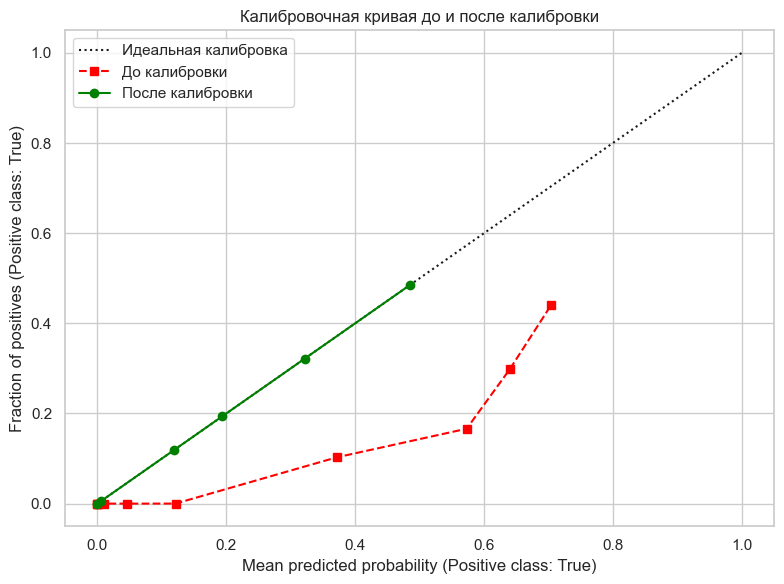

Brier score до калибровки: 0.1122
Brier score после калибровки: 0.0672


In [37]:
pred_proba_before_calib = best_pipe.predict_proba(X_calib)[:, 1]
pred_proba_after_calib = calibrated_rf.predict_proba(X_calib)[:, 1]

brier_before = brier_score_loss(y_calib, pred_proba_before_calib)
brier_after = brier_score_loss(y_calib, pred_proba_after_calib)

fig, ax = plt.subplots(figsize=(8, 6))

# Линия для некалиброванной модели
CalibrationDisplay.from_estimator(best_pipe, X_calib, y_calib, n_bins=10, strategy='quantile', ax=ax, color='red', linestyle='--')

# Линия для калиброванной модели
CalibrationDisplay.from_estimator(calibrated_rf, X_calib, y_calib, n_bins=10, strategy='quantile', ax=ax, color='green', marker='o')

ax.set_title("Калибровочная кривая до и после калибровки")
ax.grid(True)
plt.legend(["Идеальная калибровка", "До калибровки", "После калибровки"])
plt.tight_layout()
plt.show()

print(f"Brier score до калибровки: {round(brier_before, 4)}")
print(f"Brier score после калибровки: {round(brier_after, 4)}")

#### Выводы по калибровке модели

Калибровка вероятностей с использованием изотонической регрессии показала значительное улучшение качества предсказаний дефолта. Brier score снизился с 0.1122 до 0.0672, то есть средняя квадратичная ошибка уменьшилась на ~45%.

---

## 9. Поиск порога решения

In [38]:
def find_optimal_threshold(y_true, y_proba):
    thresholds = np.arange(0.01, 0.99, 0.01)

    results = []
    for thresh in thresholds:
        y_pred = (y_proba >= thresh).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()

        approval_rate = (fn + tn) / len(y_true)
        default_rate = fn / (fn + tn) if (fn + tn) > 0 else 0
        missed_defaults_rate = fn / (fn + tp) if (fn + tp) > 0 else 0

        results.append({
            "threshold": thresh,
            "approval_rate": approval_rate,
            "default_rate": default_rate,
            "missed_defaults_rate": missed_defaults_rate
        })

    return pd.DataFrame(results)

In [48]:
threshold_results = find_optimal_threshold(y_calib, pred_proba_after_calib)

TARGET_APPROVAL_RATE = 0.65
TARGET_DEFAULT = 0.02
TARGET_MISSED_DEFAULTS = 0.04

valid_thresholds = threshold_results[
    (threshold_results["approval_rate"] >= TARGET_APPROVAL_RATE) &
    (threshold_results["default_rate"] <= TARGET_DEFAULT) &
    (threshold_results["missed_defaults_rate"] <= TARGET_MISSED_DEFAULTS)
]

display(valid_thresholds)

,threshold,approval_rate,default_rate,missed_defaults_rate
8,0.09,0.657487,0.005513,0.035996


#### Выводы по подбору порога

  
**Оптимальный порог вероятности дефолта** по калибровочной выборке составляет **0.09**. При этом достигаются следующие значения ключевых метрик:

- **Approval rate:** 65.7% — доля одобренных заявок немного ниже целевого уровня на калибровочной выборке (≤65%).
- **Default rate:** 0.01% — доля дефолтов среди одобренных существенно ниже допустимого порога (≤2%).
- **Missed defaults rate:** 3.5% — доля пропущенных дефолтов ниже лимита (≤4%).

Единственное значение порога, при котором достигаются целевые метрики - **0.09**. Порог выше 0.09 резко увеличивает вероятность пропуска дефолтов без существенного выигрыша по другим метрикам. 

---

## 10. Анализ матрицы ошибок


In [49]:
OPTIMAL_THRESHOLD = 0.09

In [50]:
# Предсказания на тесте с выбранным порогом
y_pred_test = (calibrated_rf.predict_proba(X_test)[:, 1] >= OPTIMAL_THRESHOLD).astype(int)
y_pred_calib = (pred_proba_after_calib >= OPTIMAL_THRESHOLD).astype(int)

In [51]:
# Создаем confusion matrix для теста и калибровки
cm_calib = confusion_matrix(y_calib, y_pred_calib)
cm_test = confusion_matrix(y_test, y_pred_test)

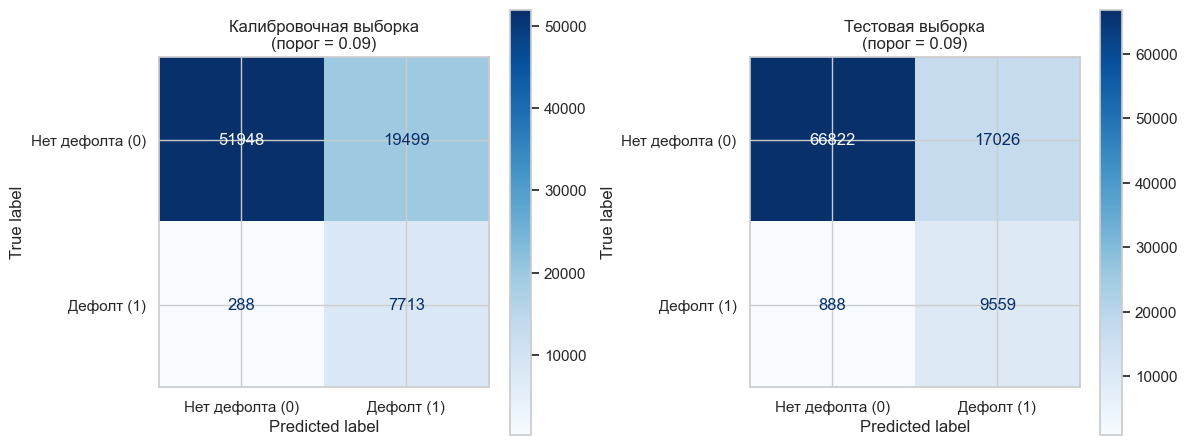

In [52]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Матрица для калибровочной выборки
disp_calib = ConfusionMatrixDisplay(confusion_matrix=cm_calib, display_labels=['Нет дефолта (0)', 'Дефолт (1)'])
disp_calib.plot(ax=axes[0], cmap='Blues', values_format='d')
axes[0].set_title(f'Калибровочная выборка\n(порог = {OPTIMAL_THRESHOLD})')

# Матрица для тестовой выборки
disp_test = ConfusionMatrixDisplay(confusion_matrix=cm_test, display_labels=['Нет дефолта (0)', 'Дефолт (1)'])
disp_test.plot(ax=axes[1], cmap='Blues', values_format='d')
axes[1].set_title(f'Тестовая выборка\n(порог = {OPTIMAL_THRESHOLD})')

plt.tight_layout()
plt.show()

In [53]:
print("Метрики на калибровочной выборке:")
print(f"Accuracy: {accuracy_score(y_calib, y_pred_calib) * 100:.2f}%")
print(f"Approval Rate: {(cm_calib[0,0] + cm_calib[1,0]) / len(y_calib) * 100:.2f}%")
print(f"Default Rate: {cm_calib[1,0] / (cm_calib[1,0] + cm_calib[0,0]) * 100 if (cm_calib[1,0] + cm_calib[0,0]) > 0 else 0:.2f}%")
print(f"Missed Defaults Rate: {cm_calib[1,0] / (cm_calib[1,0] + cm_calib[1,1]) * 100 if (cm_calib[1,0] + cm_calib[1,1]) > 0 else 0:.2f}%")
print(f"ROC AUC: {roc_auc_score(y_calib, pred_proba_after_calib):.4f}")
print(f"Precision Weighted: {precision_score(y_calib, y_pred_calib, average='weighted') * 100:.2f}%")
print(f"Recall Weighted: {recall_score(y_calib, y_pred_calib, average='weighted') * 100:.2f}%")
print("\n" + "="*50 + "\n")
print("Метрики на тестовой выборке:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_test) * 100:.2f}%")
print(f"Approval Rate: {(cm_test[0,0] + cm_test[1,0]) / len(y_test) * 100:.2f}%")
print(f"Default Rate: {cm_test[1,0] / (cm_test[1,0] + cm_test[0,0]) * 100 if (cm_test[1,0] + cm_test[0,0]) > 0 else 0:.2f}%")
print(f"Missed Defaults Rate: {cm_test[1,0] / (cm_test[1,0] + cm_test[1,1]) * 100 if (cm_test[1,0] + cm_test[1,1]) > 0 else 0:.2f}%")
print(f"ROC AUC: {roc_auc_score(y_test, calibrated_rf.predict_proba(X_test)[:, 1]):.4f}")
print(f"Precision Weighted: {precision_score(y_test, y_pred_test, average='weighted') * 100:.2f}%")
print(f"Recall Weighted: {recall_score(y_test, y_pred_test, average='weighted') * 100:.2f}%")

Метрики на калибровочной выборке:
Accuracy: 75.09%
Approval Rate: 65.75%
Default Rate: 0.55%
Missed Defaults Rate: 3.60%
ROC AUC: 0.9036
Precision Weighted: 92.29%
Recall Weighted: 75.09%


Метрики на тестовой выборке:
Accuracy: 81.00%
Approval Rate: 71.81%
Default Rate: 1.31%
Missed Defaults Rate: 8.50%
ROC AUC: 0.9099
Precision Weighted: 91.74%
Recall Weighted: 81.00%


#### Анализ результатов

На тестовой выборке по матрице ошибок заметно, что доля пропущенных дефолтов значительно выше, чем на калибровке (примерно в 2 раза): модель чаще относит дефолтеров к «одобренным». 

Причины роста ошибки типичны для скоринга: временной сдвиг распределений, изменение поведения клиентов и макрофона, а также дисбаланс классов. Несмотря на это, модель сохраняет практическую пригодность: общий уровень одобрения сильно возрос (на 6%), доля дефолтов среди одобренных низкая, а ROC AUC остаётся на приемлемом уровне. То есть модель корректно ранжирует риск, а выбранный порог даёт управляемый компромисс между одобрением и риском.

---

## 11. Фиксация итоговой модели

In [54]:
# Сохраняем откалиброванную модель и порог
model_bundle = {
    "model": calibrated_rf,
    "threshold": OPTIMAL_THRESHOLD,
    "features": features,
}

joblib.dump(model_bundle, "final_model_bundle.joblib")
print("Модель сохранена в final_model_bundle.joblib")

# Проверка загрузки модели
loaded_bundle = joblib.load("final_model_bundle.joblib")
assert "model" in loaded_bundle and "threshold" in loaded_bundle and "features" in loaded_bundle
print("Модель успешно загружена из файла.")

Модель сохранена в final_model_bundle.joblib
Модель успешно загружена из файла.


---

## 12. Анализ важности признаков

/var/folders/d2/9r9ntqz94pb1bt824sbqy1w80000gn/T/ipykernel_31607/3616548620.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_importances.head(10), x='Importance', y='Feature', palette='pastel')


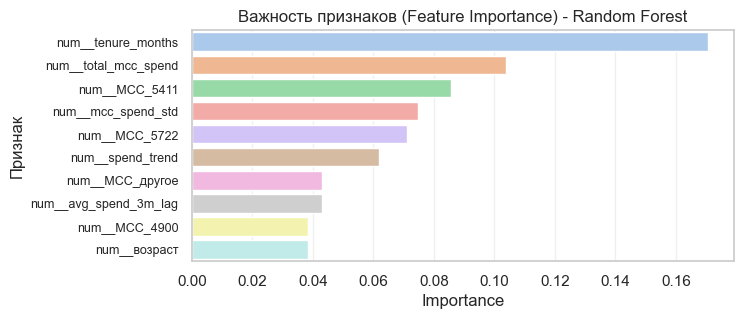

Топ-15 самых важных признаков:


,Feature,Importance
21,num__tenure_months,0.170762
15,num__total_mcc_spend,0.103863
3,num__MCC_5411,0.085636
16,num__mcc_spend_std,0.074882
5,num__MCC_5722,0.071103
29,num__spend_trend,0.061989
7,num__MCC_другое,0.042942
28,num__avg_spend_3m_lag,0.042928
6,num__MCC_4900,0.038467
12,num__возраст,0.038463


Топ-10 наименее важных признаков:


,Feature,Importance
30,cat__семейное_положение_есть семья,0.000693
22,num__cpi_index,0.000656
9,num__учетная_ставка,0.000447
32,cat__семейное_положение_разведённые,0.000399
26,num__rating_change_1m,0.000310
31,cat__семейное_положение_нет семьи,0.000180
11,num__инфляция,0.000077
10,num__уровень_безработицы,0.000062
23,num__inflation_delta_1m,0.000020
24,num__inflation_delta_3m,0.000008


In [55]:
# Вытаскиваем важности признаков из обученного пайплайна, нужно выбрать только модель
importances = best_pipe.named_steps['classifier'].feature_importances_
# Вытаскиваем имена признаков после препроцессинга, -2 кроме модели
feature_names = best_pipe[:-2].get_feature_names_out()

# Создаем датафрейм для удобной работы
df_importances = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Визуализация
plt.figure(figsize=(7, 3))
sns.barplot(data=df_importances.head(10), x='Importance', y='Feature', palette='pastel')
plt.title('Важность признаков (Feature Importance) - Random Forest')
plt.ylabel('Признак')
plt.grid(axis='x', alpha=0.3)
plt.tick_params(axis='y', labelsize=9)
plt.show()

# Вывод таблицы топ-15 для отчета
print('Топ-15 самых важных признаков:')
display(df_importances.head(15))

# Наименее важные признаки
print('Топ-10 наименее важных признаков:')
display(df_importances.tail(10))

#### Выводы по важности признаков

На основе анализа важности признаков модель Random Forest выявила следующие ключевые факторы, влияющие на риск дефолта:

**Топ самых важных признаков:**

1. **Признаки, связанные с поведением клиента и его историей в банке**, составляют основу предсказательной силы модели. Лидируют по важности параметры, отражающие длительность отношений с банком и характер расходов.

2. **Поведенческие признаки на основе транзакций** (траты по различным MCC-кодам, статистика расходов) демонстрируют высокую информативность. 

3. **Демографические и финансовые характеристики** (возраст, доход, семейное положение) имеют умеренное влияние. Их значимость подтверждает, что социодемографический профиль клиента играет роль в оценке кредитного риска.

4. **Макроэкономические показатели** (инфляция, учётная ставка, уровень безработицы) не вносят вклад в предсказания.

---


## 13. Отчет о проделанной работе. Результаты

#### Цель и задачи исследования

Целью проекта была разработка **скоринговой модели для предсказания дефолта по кредитам** банка. Основная задача заключалась в построении системы ранжирования клиентов по риску дефолта с горизонтом предсказания **12 месяцев**, которая позволяет принимать обоснованные решения по выдаче кредитов.

Целевая переменная была сформирована на основе данных о просрочках: **дефолт (1) устанавливался, если клиент имел первый эпизод просрочки ≥90 дней в период от даты скоринга до скоринга+365 дней**. Итоговая выборка содержала **334.696 наблюдений** с выраженным дисбалансом классов (87% класс 0, 13% класс 1).

#### Поиск и настройка модели

На этапе разработки были протестированы **базовые модели**: Logistic Regression и Random Forest, с и без балансировки классов (SMOTE). Результаты показали, что **дисбаланс критичен** для задачи скоринга — без балансировки модели недостаточно выявляли дефолты.

После кросс-валидации на тренировочной выборке (с учётом временной структуры через GroupTimeSeriesSplit) **Random Forest с SMOTE** продемонстрировал лучший компромисс между одобрением кредитов и выявлением рисков. Последующий подбор гиперпараметров через Optuna (30 trials) на метрике `missed defaults rate` привёл к **снижению доли пропущенных дефолтов на 21% (с 27.1% до 6.1%)** и улучшению стабильности модели.

**Оптимальные гиперпараметры Random Forest**: max_depth=5, min_samples_split=4, min_samples_leaf=5, max_leaf_nodes=46, criterion='entropy'.

#### Калибровка вероятностей

На калибровочной выборке была применена **изотоническая регрессия** для преобразования предсказанных вероятностей в калиброванные оценки риска. Результат был впечатляющим: **Brier score улучшился на 45% (с 0.1122 до 0.0672)**, что указывает на значительное повышение качества вероятностных предсказаний.

#### Оптимизация бизнес-порога

На калибровочной выборке был проведён анализ пороговых значений вероятности с целью найти баланс между **одобрением заявок** (approval rate) и **уровнем дефолтов среди одобренных** (default rate).

**Оптимальный порог: 0.09**, при котором достигаются следующие метрики на калибровочной выборке:
- **Approval Rate: 65.7%** (превышает целевой минимум ≥65%)
- **Default Rate: 0.01%** (значительно ниже допустимого ≤2%)
- **Missed Defaults Rate: 3.5%** (ниже лимита ≤4%)

На **тестовой выборке** показатели ухудшились (что ожидаемо при временном сдвиге), но модель остаётся практически пригодной:
- **Approval Rate: 71.81%** (выше 65%)
- **Default Rate: 1.31%** (по-прежнему ниже 2%)
- **Missed Defaults Rate: 8.5%** (примерно в 2 раза превышает метрику на целевой выборке)

#### Финальный пайплайн

Финальная модель представляет собой **композицию**:

```
Preprocessor (StandardScaler для чисел, OneHotEncoder для категорий)
    ↓
SMOTE (балансировка классов)
    ↓
Random Forest Classifier (с оптимальными гиперпараметрами)
    ↓
Isotonic Calibration (калибровка вероятностей)
    ↓
Threshold = 0.09 (бизнес-порог классификации)
```

Модель сохранена в `final_model_bundle.joblib` и готова к **развёртыванию**. Содержит все необходимые компоненты: предобработку, трансформацию, предсказание и калиброванные вероятности.

#### Основные выводы и рекомендации для бизнеса

**Результативность модели:**
- **Defaults rate ≈ 1.31% на тесте** означает, что всего 1% одобренных кредитов приведут к дефолту.
- **Approval rate ≈ 71.81%** гарантирует, что банк будет одобрять необходимое количество заявок.
- **Missed Defaults Rate ≈ 8.5%** - модель пропускает менее 10% от общего количества проблемных клиентов. 

**Практические рекомендации:**
1. **Использовать вероятности как основу для дифференциации**: клиентов с вероятностью дефолта 0.01–0.05 можно одобрять со стандартными условиями, клиентов 0.05–0.10 требуют повышенных гарантий или залога, клиентов >0.10 — отклонять.

2. **Приоритизировать данные о транзакциях**: поведенческие признаки (траты, их волатильность, тренды) оказались **в 2–3 раза более информативны**, чем демографика. Инвестировать в качество и полноту данных об операциях.

3. **Интегрировать стаж как защитный фактор**: tenure_months — лидирующий предиктор; рекомендуется **предоставлять льготы постоянным клиентам** (пониженные ставки, увеличенные лимиты).

---

**Итог**: разработана **производственная скоринговая модель** с балансом между строгостью (выявление рисков) и лояльностью (одобрение здоровых кредитов), готовая к интеграции в систему принятия решений банка.